In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

In [83]:
data_path = Path("../results/results_mine_alligned_bloomz_mass_fixed")

In [84]:
data_files={}
for file_path in data_path.iterdir():
    if file_path.is_file() and file_path.name.endswith(".csv"):
        data_files[file_path.name[:-4]] = pd.read_csv(file_path)

In [85]:
data_files.keys()

dict_keys(['x2_results_df', 'x5_results_df', 'x4_results_df', 'x3_results_df', 'x8_bn_results_df', 'x1_results_df', 'x6_results_df', 'x8_en_pbn_results_df', 'x7_results_df', 'x8_bn_pbn_results_df', 'x8_results_df'])

In [128]:
from probad.schema import TestItem, validate_items
from probad.utils import load_bengali_stopwords
from pathlib import Path
import json
from typing import Any

DATA_PATH = Path("/Users/koyeldas/Documents/projects/bn-proverbs-in-context/data")

train_data = list(TestItem.load_items(DATA_PATH/"train.jsonl"))
test_data = list(TestItem.load_items(DATA_PATH/"test.jsonl"))
val_data = list(TestItem.load_items(DATA_PATH/"val.jsonl"))

source = DATA_PATH / "stopwords-bn/stopwords-bn.json"
try:
    data: Any = json.loads(source.read_text(encoding="utf-8-sig"))
except FileNotFoundError as exc:
    raise FileNotFoundError(f"Stopword file not found: {source}") from exc
except json.JSONDecodeError as exc:
    raise ValueError(
        f"Invalid JSON in stopword file {source}: "
        f"line {exc.lineno}, column {exc.colno}: {exc.msg}"
    ) from exc

BN_STOPWORDS =  frozenset([word.strip() for word in data])


import re
import numpy as np, pandas as pd

EN_STOP = {"the", "a", "an", "and", "or", "but", "to", "of", "in", "on", "at", "for", "with", "is", "are", "was",
           "were", "be", "been", "it", "its", "that", "this", "he", "she", "they", "his", "her", "their", "them",
           "you", "your", "i", "me", "my", "we", "our", "so", "as", "by", "from", "not", "no", "do", "does", "did",
           "has", "have", "had", "will", "would", "can", "could", "if", "then", "than", "there", "what", "who"}

def words(text, lang):
    toks = re.findall(r"\w+", text.lower())                    # \w covers Bengali letters; drops । , ? etc.
    stop = BN_STOPWORDS if lang == "bn" else EN_STOP
    return {t for t in toks if t not in stop and len(t) > 1}

def context_words(item, lang):
    """All turns except the one where the proverb is said."""
    b = item[lang]
    turns = b["turns"]
    last = max(i for i, t in enumerate(turns) if t["speaker"] == b["proverb_speaker"])   # proverb = speaker's last turn
    return words(" ".join(t["text"] for i, t in enumerate(turns) if i != last), lang)

def overlap_pick(item, lang, keys):
    """1 if the correct option has the strictly highest overlap with the context, 0.5 on a tie, else 0."""
    ctx = context_words(item, lang)
    o = item[lang]["options"]
    ov = {k: len(ctx & words(o[k], lang)) for k in keys}
    best = max(ov.values())
    winners = [k for k, v in ov.items() if v == best]
    return (1 / len(winners)) if "correct" in winners else 0.0

rows = []
for it in test_data:
    d = it.model_dump()
    for lang in ("en", "bn"):
        rows.append({"item_id": d["item_id"], "lang": lang,
                     "x1 (correct vs literal)": overlap_pick(d, lang, ("correct", "literal")),
                     "E2 (correct vs plausible)": overlap_pick(d, lang, ("correct", "plausible")),
                     "x5 (all three)": overlap_pick(d, lang, ("correct", "literal", "plausible"))})
ov = pd.DataFrame(rows)
print(ov.groupby("lang").mean(numeric_only=True).round(3))

bl = data_files["x1_results_df"].assign(lang=lambda d: d["label"].str[-2:])[["item_id", "lang", "correct"]]
m = ov.merge(bl, on=["item_id", "lang"])
m["shortcut_right"] = m["x1 (correct vs literal)"] == 1
display(pd.crosstab([m["lang"], m["shortcut_right"]], m["correct"], margins=True))
display(m.groupby(["lang", "shortcut_right"])["correct"].mean().round(3))   # BLOOMZ accuracy when the cue works vs not

      x1 (correct vs literal)  E2 (correct vs plausible)  x5 (all three)
lang                                                                    
bn                       0.67                      0.392           0.322
en                       0.75                      0.312           0.284


correct              False  True   All
lang shortcut_right                   
bn   False              41   289   330
     True               48   222   270
en   False               8   236   244
     True                7   349   356
All                    104  1096  1200

lang  shortcut_right
bn    False             0.876
      True              0.822
en    False             0.967
      True              0.980
Name: correct, dtype: float64

In [86]:

FIG = data_path / "new_figs_x"; FIG.mkdir(parents=True, exist_ok=True)

RUNS = {"x1": data_files["x1_results_df"], "x2": data_files["x2_results_df"], "x3": data_files["x3_results_df"], "x4": data_files["x4_results_df"],
        "x5": data_files["x5_results_df"], "x6": data_files["x6_results_df"], "x7": data_files["x7_results_df"], "x8": data_files["x8_results_df"], "x8_bn": data_files["x8_bn_results_df"],
       "x8_en_pbn": data_files["x8_en_pbn_results_df"], "x8_bn_pbn": data_files["x8_bn_pbn_results_df"]}
NEG_PAIRS     = [("x1_en", "x2_en"), ("x1_bn", "x2_bn")]   # (what does X mean?, what does X NOT mean?)
KNOW_PAIRS    = [("x4_en", "x1_en"), ("x4_bn", "x1_bn")]   # (meaning without context, meaning in context)
CONTROL_PAIRS = [("x1_en", "x7_en"), ("x1_bn", "x7_bn")]   # (with question, no question)
X6_REF, X8_REF = "x6_romanised", "x8_en_C0"                    # baselines for the render / persona plots

ALL = pd.concat([df.assign(exp=name) for name, df in RUNS.items()], ignore_index=True)
ALL["gold"], ALL["pred"] = ALL["gold"].str.lower(), ALL["pred"].str.lower()
print("labels:", sorted(ALL["label"].unique()))
sub = lambda label: ALL[ALL["label"] == label]
have = lambda *labels: all((ALL["label"] == l).any() for l in labels) or print("skip, label missing:", labels)

labels: ['x1_bn', 'x1_en', 'x2_bn', 'x2_en', 'x3_bn', 'x3_en', 'x4_bn', 'x4_en', 'x5_bn', 'x5_en', 'x6_bengali', 'x6_gloss', 'x6_gloss_only', 'x6_romanised', 'x7_bn', 'x7_en', 'x8_bn_C0', 'x8_bn_C1a', 'x8_bn_C1b', 'x8_bn_pbn_C0', 'x8_bn_pbn_C1a', 'x8_bn_pbn_C1b', 'x8_en_C0', 'x8_en_C1a', 'x8_en_C1b', 'x8_en_pbn_C0', 'x8_en_pbn_C1a', 'x8_en_pbn_C1b']


In [87]:
ALL["label"].unique()

<ArrowStringArray>
[        'x1_en',         'x1_bn',         'x2_en',         'x2_bn',
         'x3_en',         'x3_bn',         'x4_en',         'x4_bn',
         'x5_bn',         'x5_en',      'x6_gloss',  'x6_romanised',
    'x6_bengali', 'x6_gloss_only',         'x7_bn',         'x7_en',
      'x8_en_C0',     'x8_en_C1a',     'x8_en_C1b',      'x8_bn_C0',
     'x8_bn_C1a',     'x8_bn_C1b', 'x8_en_pbn_C1a',  'x8_en_pbn_C0',
 'x8_en_pbn_C1b', 'x8_bn_pbn_C1a',  'x8_bn_pbn_C0', 'x8_bn_pbn_C1b']
Length: 28, dtype: str

In [88]:
WPROMPT = pd.concat([df.assign(exp=name) for name, df in RUNS.items() if "x8" in name], ignore_index=True)

In [89]:
def item_level(df, by=("label",)):
    """Collapse option orders: one row per item. correct = share of orders right;
    correct_db = mean P(gold) > 0.5 (2 options, cancels position bias when both orders were scored)."""
    df = df.copy()
    df["p_gold"] = df.apply(lambda r: r[f"p_{r['gold']}"], axis=1)
    df["n_opts"] = df.filter(regex=r"^p_[abc]$").notna().sum(axis=1)
    keys = [k for k in dict.fromkeys([*by, "item_id", "proverb_id", "figurative"]) if k in df]
    it = df.groupby(keys, dropna=False).agg(
        correct=("correct", "mean"), p_gold=("p_gold", "mean"), margin=("margin", "mean"),
        letter_mass=("letter_mass", "mean"), n_opts=("n_opts", "first"),
        n_orders=("correct", "size")).reset_index()
    it["correct_db"] = np.where((it["n_opts"] == 2) & (it["n_orders"] >= 2), it["p_gold"] > 0.5, np.nan)
    return it

def ci(values, clusters, n=2000, seed=0):
    """95% CI of the mean, resampling whole proverbs."""
    _, inv = np.unique(np.asarray(clusters), return_inverse=True)
    s, c = np.bincount(inv, np.asarray(values, float)), np.bincount(inv)
    pick = np.random.default_rng(seed).integers(0, len(c), (n, len(c)))
    return np.percentile(s[pick].sum(1) / c[pick].sum(1), [2.5, 97.5])

def summary(df, by="label"):
    it = item_level(df, (by,))
    rows = []
    for key, g in it.groupby(by):
        lo, hi = ci(g["correct"], g["proverb_id"])
        raw = df[df[by] == key]
        rows.append({by: key, "acc": g["correct"].mean(), "ci_lo": lo, "ci_hi": hi,
                     "chance": 1 / g["n_opts"].mean(), "acc_db": g["correct_db"].mean(), "n": len(g),
                     "p_gold": g["p_gold"].mean(), "letter_mass": g["letter_mass"].median(),
                     "pred_a": (raw["pred"] == "a").mean(), "pred_b": (raw["pred"] == "b").mean(),
                     "pred_c": (raw["pred"] == "c").mean()})
    return pd.DataFrame(rows)

def paired(a, b, name_a, name_b):
    """b - a on shared items, CI over proverbs."""
    m = item_level(a, ()).merge(item_level(b, ()), on=["item_id", "proverb_id"], suffixes=("_a", "_b"))
    d = m["correct_b"] - m["correct_a"]
    lo, hi = ci(d, m["proverb_id"])
    return {"a": name_a, "b": name_b, "acc_a": m["correct_a"].mean(), "acc_b": m["correct_b"].mean(),
            "diff": d.mean(), "ci_lo": lo, "ci_hi": hi, "a_only": int((d < 0).sum()),
            "b_only": int((d > 0).sum()), "n": len(m)}

def bar(tab, title, fname, x="label"):
    fig, ax = plt.subplots(figsize=(max(4, 0.9 * len(tab) + 2), 3.5))
    ax.bar(tab[x].astype(str), tab["acc"], yerr=[tab["acc"] - tab["ci_lo"], tab["ci_hi"] - tab["acc"]],
           capsize=4, color="#4C72B0")
    for i, c in enumerate(tab["chance"]):
        ax.hlines(c, i - 0.4, i + 0.4, colors="red", linestyles="--")
    ax.set_ylim(0, 1); ax.set_ylabel("accuracy"); ax.set_title(title)
    plt.xticks(rotation=30, ha="right"); plt.tight_layout(); fig.savefig(FIG / fname, dpi=150); plt.show()

def forest(tab, title, fname):
    fig, ax = plt.subplots(figsize=(6, 0.4 * len(tab) + 1.5))
    ax.errorbar(tab["diff"], range(len(tab)), xerr=[tab["diff"] - tab["ci_lo"], tab["ci_hi"] - tab["diff"]], fmt="o")
    ax.axvline(0, color="grey", ls="--"); ax.set_yticks(range(len(tab)), tab["b"].astype(str))
    ax.set_xlabel(f"accuracy − {tab['a'].iloc[0]} (95% CI)"); ax.set_title(title)
    plt.tight_layout(); fig.savefig(FIG / fname, dpi=150); plt.show()

def heat(ax, tab, title):
    ax.imshow(tab.values, cmap="Blues")
    for (r, c), v in np.ndenumerate(tab.values):
        ax.text(c, r, v, ha="center", va="center")
    ax.set_xticks(range(tab.shape[1]), tab.columns); ax.set_yticks(range(tab.shape[0]), tab.index); ax.set_title(title)

def picked_key(df, keys, none_last=False):
    """Which option (correct / literal / plausible / none) each answer letter was. Re-creates the
    shuffle in own_mcq; assumes seed 0 unless df has a 'seed' column."""
    def keys_for(item_id, seed):
        k = list(keys)
        rng = random.Random(f"{item_id}|{seed}")
        if none_last:
            rest = [x for x in k if x != "none"]; rng.shuffle(rest); k = rest + ["none"]
        else:
            rng.shuffle(k)
        return dict(zip("abc", k))
    seeds = df["seed"] if "seed" in df else pd.Series(0, index=df.index)
    maps_ = [keys_for(i, s) for i, s in zip(df["item_id"], seeds)]
    return df.assign(pred_key=[m[p] for m, p in zip(maps_, df["pred"])],
                     gold_key=[m[g] for m, g in zip(maps_, df["gold"])])


,label,acc,ci_lo,ci_hi,chance,acc_db,n,p_gold,letter_mass,pred_a,pred_b,pred_c
0,x1_bn,0.852,0.815,0.887,0.500,NaN,600,0.794,0.857,0.432,0.568,0.000
1,x1_en,0.975,0.958,0.988,0.500,NaN,600,0.939,0.996,0.475,0.525,0.000
2,x2_bn,0.158,0.120,0.200,0.500,NaN,600,0.227,0.865,0.438,0.562,0.000
3,x2_en,0.507,0.463,0.545,0.500,NaN,600,0.499,0.975,0.073,0.927,0.000
4,x3_bn,0.168,0.132,0.208,0.333,NaN,600,0.207,0.953,0.527,0.305,0.168
5,x3_en,0.063,0.043,0.083,0.333,NaN,600,0.136,0.977,0.530,0.407,0.063
6,x4_bn,0.563,0.507,0.618,0.500,NaN,600,0.563,0.952,0.507,0.493,0.000
7,x4_en,0.903,0.870,0.933,0.500,NaN,600,0.840,0.989,0.503,0.497,0.000
8,x5_bn,0.727,0.680,0.765,0.333,NaN,600,0.654,0.883,0.310,0.235,0.455
9,x5_en,0.847,0.812,0.878,0.333,NaN,600,0.795,0.992,0.295,0.310,0.395


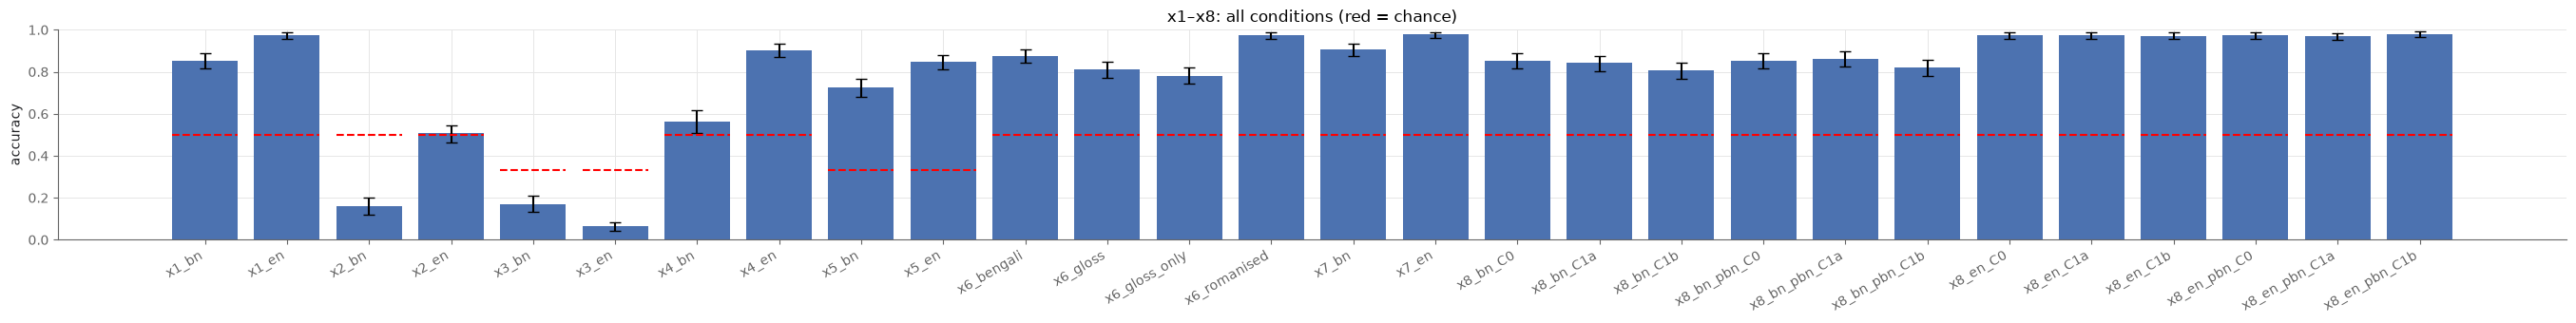

In [90]:
overview = summary(ALL)
display(overview.round(3))
bar(overview, "x1–x8: all conditions (red = chance)", "x_overview.png")

,label,acc,ci_lo,ci_hi,chance,acc_db,n,p_gold,letter_mass,pred_a,pred_b,pred_c
0,x8_bn_C0,0.852,0.815,0.887,0.5,NaN,600,0.794,0.857,0.432,0.568,0.0
1,x8_bn_C1a,0.842,0.803,0.877,0.5,NaN,600,0.794,0.934,0.445,0.555,0.0
2,x8_bn_C1b,0.807,0.765,0.843,0.5,NaN,600,0.744,0.986,0.420,0.580,0.0
3,x8_bn_pbn_C0,0.852,0.815,0.887,0.5,NaN,600,0.794,0.857,0.432,0.568,0.0
4,x8_bn_pbn_C1a,0.863,0.827,0.897,0.5,NaN,600,0.803,0.826,0.463,0.537,0.0
5,x8_bn_pbn_C1b,0.820,0.780,0.857,0.5,NaN,600,0.762,0.883,0.457,0.543,0.0
6,x8_en_C0,0.975,0.958,0.988,0.5,NaN,600,0.939,0.996,0.475,0.525,0.0
7,x8_en_C1a,0.975,0.958,0.988,0.5,NaN,600,0.938,0.996,0.478,0.522,0.0
8,x8_en_C1b,0.972,0.955,0.987,0.5,NaN,600,0.926,0.993,0.468,0.532,0.0
9,x8_en_pbn_C0,0.975,0.958,0.988,0.5,NaN,600,0.939,0.996,0.475,0.525,0.0


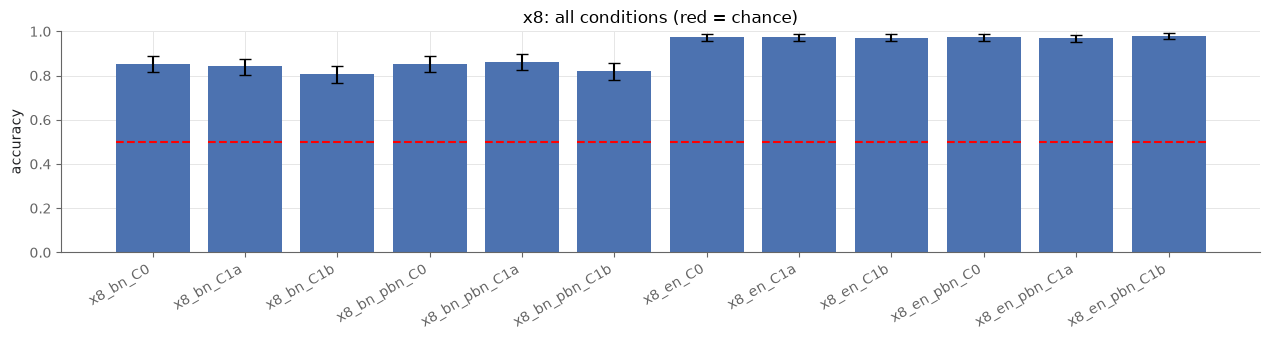

In [91]:
overview = summary(WPROMPT)
display(overview.round(3))
bar(overview, "x8: all conditions (red = chance)", "x_overview_wprompt.png")

,figurative,acc,ci_lo,ci_hi,chance,acc_db,n,p_gold,letter_mass,pred_a,pred_b,pred_c,label
0,False,0.856,0.767,0.933,0.5,NaN,90,0.810,0.898,0.389,0.611,0.0,x1_bn
1,True,0.851,0.812,0.890,0.5,NaN,510,0.791,0.849,0.439,0.561,0.0,x1_bn
0,False,0.978,0.944,1.000,0.5,NaN,90,0.909,0.995,0.422,0.578,0.0,x1_en
1,True,0.975,0.957,0.990,0.5,NaN,510,0.944,0.997,0.484,0.516,0.0,x1_en


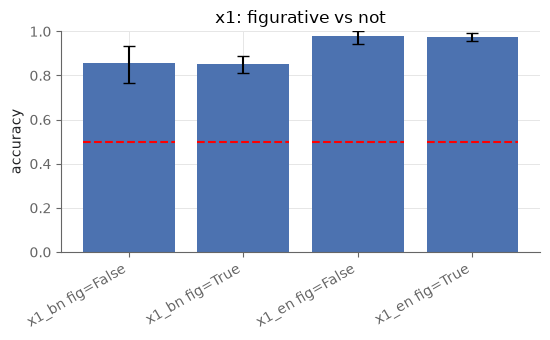

In [92]:
x1_fig = pd.concat([summary(g, by="figurative").assign(label=l) for l, g in RUNS["x1"].groupby("label")])
display(x1_fig.round(3))
bar(x1_fig.assign(cond=x1_fig["label"] + " fig=" + x1_fig["figurative"].astype(str)),
    "x1: figurative vs not", "x1_figurative.png", x="cond")


In [93]:
neg_rows = []
for pos_l, neg_l in NEG_PAIRS:
    if not have(pos_l, neg_l):
        continue
    m = item_level(sub(pos_l), ()).merge(item_level(sub(neg_l), ()), on="item_id", suffixes=("_pos", "_neg"))
    picked_correct_pos = m["correct_pos"] >= 0.5          # x1 gold = correct meaning
    picked_correct_neg = m["correct_neg"] < 0.5           # x2 gold = literal, so a miss = picked correct
    neg_rows.append({"pos": pos_l, "neg": neg_l, "acc_pos": m["correct_pos"].mean(), "acc_neg": m["correct_neg"].mean(),
                     "sum": m["correct_pos"].mean() + m["correct_neg"].mean(),       # ~1.0 = ignores NOT
                     "same_option_both": (picked_correct_pos == picked_correct_neg).mean(),
                     "both_right": ((m["correct_pos"] >= 0.5) & (m["correct_neg"] >= 0.5)).mean(), "n": len(m)})
neg_tab = pd.DataFrame(neg_rows)
display(neg_tab.round(3))

,pos,neg,acc_pos,acc_neg,sum,same_option_both,both_right,n
0,x1_en,x2_en,0.975,0.507,1.482,0.508,0.487,600
1,x1_bn,x2_bn,0.852,0.158,1.010,0.937,0.037,600


x3 pick rates (chance 1/3 each)
 pred_key  literal   none  plausible
label                              
x3_bn       0.363  0.168      0.468
x3_en       0.185  0.063      0.752


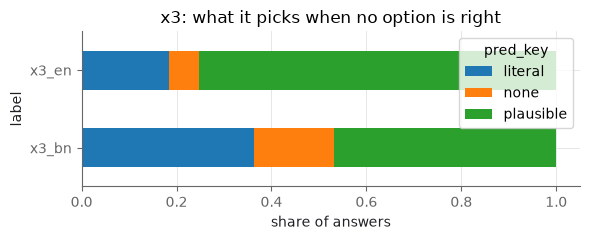

In [94]:
import random
x3 = picked_key(RUNS["x3"].assign(gold=lambda d: d["gold"].str.lower(), pred=lambda d: d["pred"].str.lower()),
                ("literal", "plausible", "none"), none_last=True)
x3_tab = x3.groupby("label")["pred_key"].value_counts(normalize=True).unstack().fillna(0)
print("x3 pick rates (chance 1/3 each)\n", x3_tab.round(3))
x3_tab.plot.barh(stacked=True, figsize=(6, 0.5 * len(x3_tab) + 1.5), title="x3: what it picks when no option is right")
plt.xlabel("share of answers"); plt.tight_layout() 
plt.show()


x4_en -> x1_en 
 uses          doesn't use  uses
knows                          
doesn't know            5    53
knows                  10   532
x4_bn -> x1_bn 
 uses          doesn't use  uses
knows                          
doesn't know           56   206
knows                  33   305


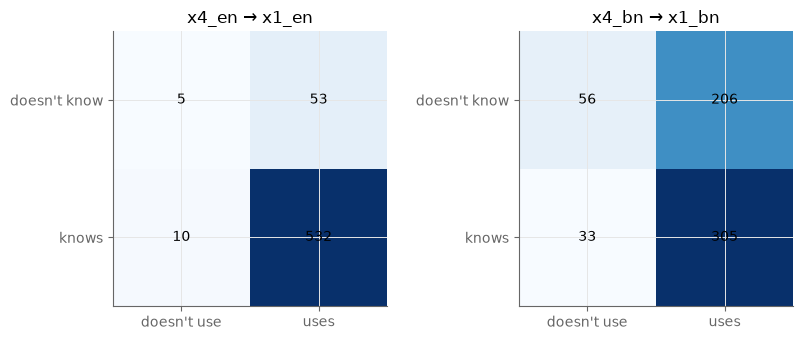

,know,use,knows_meaning,acc_in_context,ci_lo,ci_hi,n
0,x4_en,x1_en,False,0.914,0.814,0.983,58
1,x4_en,x1_en,True,0.982,0.968,0.993,542
2,x4_bn,x1_bn,False,0.786,0.725,0.843,262
3,x4_bn,x1_bn,True,0.902,0.861,0.939,338


In [95]:

know_rows, pairs_ok = [], [p for p in KNOW_PAIRS if have(*p)]
if pairs_ok:
    fig, axes = plt.subplots(1, len(pairs_ok), figsize=(4.2 * len(pairs_ok), 3.5), squeeze=False)
for ax, (k_l, u_l) in zip(axes[0] if pairs_ok else [], pairs_ok):
    m = item_level(sub(u_l), ()).merge(item_level(sub(k_l), ())[["item_id", "correct"]],
                                       on="item_id", suffixes=("", "_know"))
    m["knows"], m["uses"] = m["correct_know"] >= 0.5, m["correct"] >= 0.5
    for kn, g in m.groupby("knows"):
        lo, hi = ci(g["correct"], g["proverb_id"])
        know_rows.append({"know": k_l, "use": u_l, "knows_meaning": kn, "acc_in_context": g["correct"].mean(),
                          "ci_lo": lo, "ci_hi": hi, "n": len(g)})
    quad = pd.crosstab(m["knows"].map({True: "knows", False: "doesn't know"}),
                       m["uses"].map({True: "uses", False: "doesn't use"}))
    print(k_l, "->", u_l, "\n", quad); heat(ax, quad, f"{k_l} → {u_l}")
if pairs_ok:
    plt.tight_layout()
    plt.show()
know_tab = pd.DataFrame(know_rows)
display(know_tab.round(3))


x5 pick rates (chance 1/3 each)
 pred_key  correct  literal  plausible  literal_share_of_errors
label                                                         
x5_bn       0.727    0.122      0.152                    0.445
x5_en       0.847    0.020      0.133                    0.130


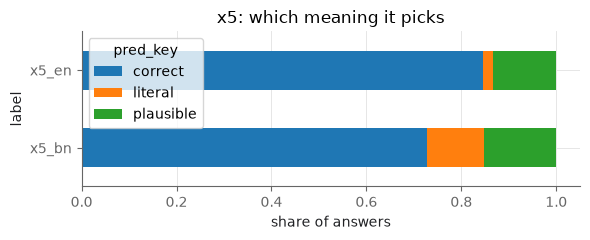

In [96]:
x5 = picked_key(RUNS["x5"].assign(gold=lambda d: d["gold"].str.lower(), pred=lambda d: d["pred"].str.lower()),
                ("correct", "literal", "plausible"))
ok = (x5["gold_key"] == "correct").mean()
if ok < 1:
    print(f"WARNING x5: option order re-created for only {ok:.0%} of rows; add a 'seed' column per run")
x5_tab = x5.groupby("label")["pred_key"].value_counts(normalize=True).unstack().fillna(0)
x5_tab["literal_share_of_errors"] = x5_tab["literal"] / (x5_tab["literal"] + x5_tab["plausible"])
print("x5 pick rates (chance 1/3 each)\n", x5_tab.round(3))
x5_tab[["correct", "literal", "plausible"]].plot.barh(stacked=True, figsize=(6, 0.5 * len(x5_tab) + 1.5),
                                                      title="x5: which meaning it picks")
plt.xlabel("share of answers"); plt.tight_layout()
plt.show()

,a,b,acc_a,acc_b,diff,ci_lo,ci_hi,a_only,b_only,n
0,x6_romanised,x6_bengali,0.975,0.877,-0.098,-0.128,-0.070,61,2,600
1,x6_romanised,x6_gloss,0.975,0.810,-0.165,-0.200,-0.130,101,2,600
2,x6_romanised,x6_gloss_only,0.975,0.780,-0.195,-0.232,-0.157,121,4,600


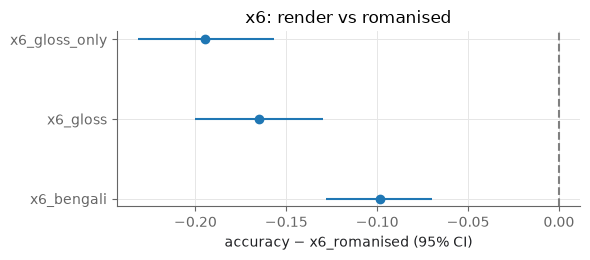

In [97]:
if have(X6_REF):
    x6_tab = pd.DataFrame([paired(sub(X6_REF), g, X6_REF, l) for l, g in RUNS["x6"].groupby("label") if l != X6_REF])
    display(x6_tab.round(3))
    forest(x6_tab, "x6: render vs romanised", "x6_render.png")


In [98]:
ctrl = pd.DataFrame([paired(sub(a), sub(b), a, b) for a, b in CONTROL_PAIRS if have(a, b)])
display(ctrl.round(3))   # diff ~0 = question not used

,a,b,acc_a,acc_b,diff,ci_lo,ci_hi,a_only,b_only,n
0,x1_en,x7_en,0.975,0.977,0.002,-0.008,0.013,5,6,600
1,x1_bn,x7_bn,0.852,0.905,0.053,0.023,0.085,18,50,600


,a,b,acc_a,acc_b,diff,ci_lo,ci_hi,a_only,b_only,n
0,x8_en_C0,x8_en_C1a,0.975,0.975,0.000,-0.007,0.007,2,2,600
1,x8_en_C0,x8_en_C1b,0.975,0.972,-0.003,-0.013,0.007,5,3,600


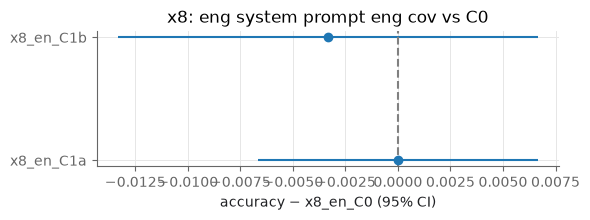

In [99]:
if have(X8_REF):
    x8_tab = pd.DataFrame([paired(sub(X8_REF), g, X8_REF, l) for l, g in RUNS["x8"].groupby("label") if l != X8_REF])
    display(x8_tab.round(3))
    forest(x8_tab, "x8: eng system prompt eng cov vs C0", "x8_en_pen_system.png")

,a,b,acc_a,acc_b,diff,ci_lo,ci_hi,a_only,b_only,n
0,x8_bn_C0,x8_bn_C1a,0.852,0.842,-0.010,-0.028,0.007,16,10,600
1,x8_bn_C0,x8_bn_C1b,0.852,0.807,-0.045,-0.072,-0.020,38,11,600


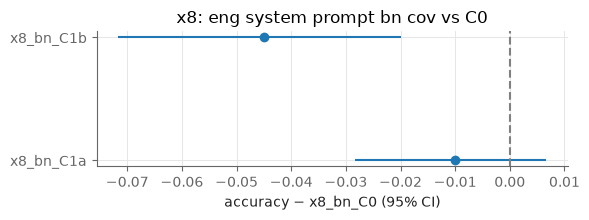

In [100]:
REF = "x8_bn_C0"
if have(REF):
    x8_tab = pd.DataFrame([paired(sub(REF), g, REF, l) for l, g in RUNS["x8_bn"].groupby("label") if l != REF])
    display(x8_tab.round(3))
    forest(x8_tab, "x8: eng system prompt bn cov vs C0", "x8_bn_pen_system.png")

,a,b,acc_a,acc_b,diff,ci_lo,ci_hi,a_only,b_only,n
0,x8_bn_pbn_C0,x8_bn_pbn_C1a,0.852,0.863,0.012,-0.007,0.03,12,19,600
1,x8_bn_pbn_C0,x8_bn_pbn_C1b,0.852,0.820,-0.032,-0.055,-0.01,33,14,600


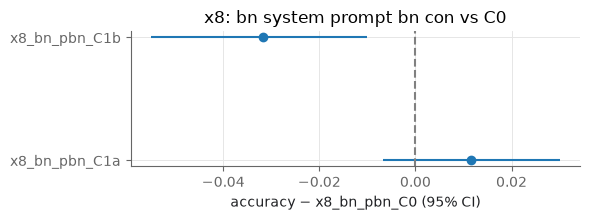

In [101]:
REF = "x8_bn_pbn_C0"
if have(REF):
    x8_tab = pd.DataFrame([paired(sub(REF), g, REF, l) for l, g in RUNS["x8_bn_pbn"].groupby("label") if l != REF])
    display(x8_tab.round(3))
    forest(x8_tab, "x8: bn system prompt bn con vs C0", "x8_bn_pbn_system.png")

,a,b,acc_a,acc_b,diff,ci_lo,ci_hi,a_only,b_only,n
0,x8_en_pbn_C0,x8_en_pbn_C1a,0.975,0.970,-0.005,-0.013,0.002,4,1,600
1,x8_en_pbn_C0,x8_en_pbn_C1b,0.975,0.978,0.003,-0.007,0.013,5,7,600


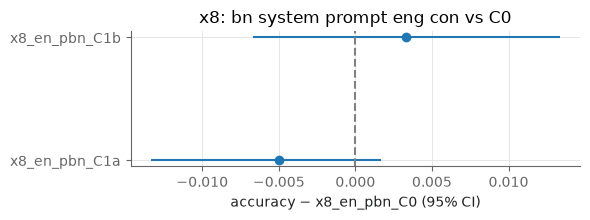

In [102]:
REF = "x8_en_pbn_C0"
if have(REF):
    x8_tab = pd.DataFrame([paired(sub(REF), g, REF, l) for l, g in RUNS["x8_en_pbn"].groupby("label") if l != REF])
    display(x8_tab.round(3))
    forest(x8_tab, "x8: bn system prompt eng con vs C0", "x8_en_pbn_system.png")

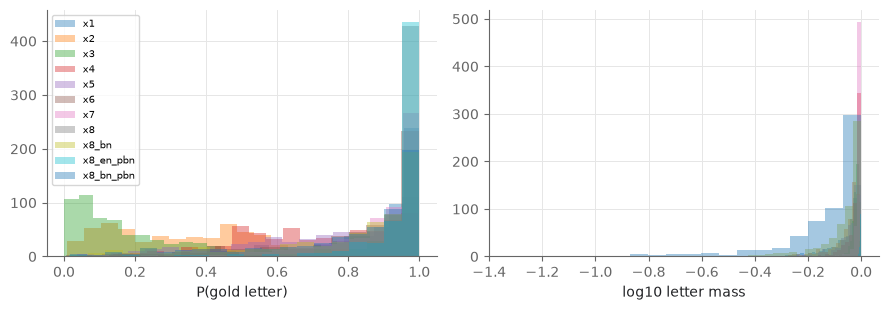

In [103]:

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for name, df in RUNS.items():
    it = item_level(df, ())
    axes[0].hist(it["p_gold"], bins=20, alpha=0.4, label=name)
    axes[1].hist(np.log10(it["letter_mass"]), bins=20, alpha=0.4, label=name)
axes[0].set_xlabel("P(gold letter)"); axes[1].set_xlabel("log10 letter mass"); axes[0].legend(fontsize=7)
plt.tight_layout(); fig.savefig(FIG / "x_confidence.png", dpi=150); plt.show()

In [104]:
RUNS.keys()

dict_keys(['x1', 'x2', 'x3', 'x4', 'x5', 'x6', 'x7', 'x8', 'x8_bn', 'x8_en_pbn', 'x8_bn_pbn'])

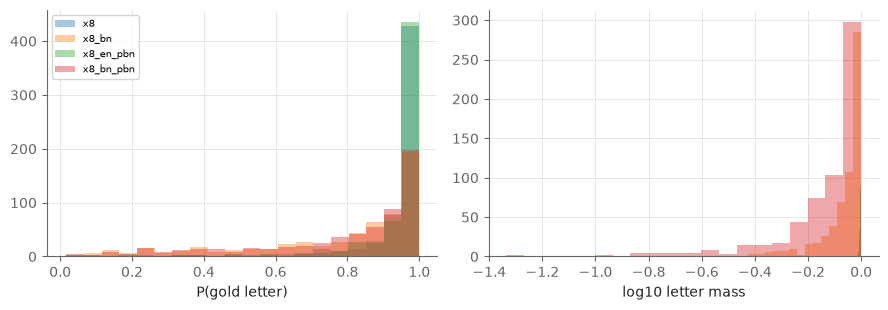

In [105]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for name in ['x8', 'x8_bn', 'x8_en_pbn', 'x8_bn_pbn']:
    df = RUNS[name]
    it = item_level(df, ())
    axes[0].hist(it["p_gold"], bins=20, alpha=0.4, label=name)
    axes[1].hist(np.log10(it["letter_mass"]), bins=20, alpha=0.4, label=name)
axes[0].set_xlabel("P(gold letter)"); axes[1].set_xlabel("log10 letter mass"); axes[0].legend(fontsize=7)
plt.tight_layout(); fig.savefig(FIG / "x_confidence_prompt.png", dpi=150); plt.show()

In [106]:
PROMPT_RUNS = {"en": RUNS["x8"], "bn": RUNS["x8_bn"]}
ORDER = ["C0", "C1a", "C1b", "C1c"]                    # C1c = GEPA prompt (label x8_en_C1c / x8_bn_C1c)
LANG_COLOR = {"en": "#2a78d6", "bn": "#eb6834"}
GAIN, LOSS, MID = "#2a78d6", "#e34948", "#f0efec"      # fixed / broken / neutral
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True,
                     "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True, "font.size": 10})

def prompt_items(df):
    it = item_level(df)
    it["cond"] = it["label"].str.split("_").str[-1]
    return it[it["cond"].isin(ORDER)]

P = {lang: prompt_items(df) for lang, df in PROMPT_RUNS.items()}
conds = [c for c in ORDER if any((P[l]["cond"] == c).any() for l in P)]
right = {l: (it.pivot_table(index=["item_id", "proverb_id"], columns="cond", values="correct") >= 0.5)[
             [c for c in conds if c in set(it["cond"])]] for l, it in P.items()}
pgold = {l: it.pivot_table(index="item_id", columns="cond", values="p_gold")[right[l].columns] for l, it in P.items()}



In [107]:
rows = []
for l, it in P.items():
    R = right[l]
    for c in R.columns:
        g = it[it["cond"] == c]
        lo, hi = ci(g["correct"], g["proverb_id"])
        raw = sub(g["label"].iloc[0])
        rows.append({"lang": l, "cond": c, "acc": g["correct"].mean(), "ci_lo": lo, "ci_hi": hi,
                     "acc_db": g["correct_db"].mean(), "pred_a": (raw["pred"] == "a").mean(),
                     "pred_b": (raw["pred"] == "b").mean(),
                     "fixed_vs_C0": int((R[c] & ~R["C0"]).sum()), "broken_vs_C0": int((~R[c] & R["C0"]).sum()),
                     "only_this_prompt": int((R[c] & ~R.drop(columns=c).any(axis=1)).sum()), "n": len(g)})
    any_right = R.any(axis=1).astype(float)
    lo, hi = ci(any_right, R.index.get_level_values("proverb_id"))
    rows.append({"lang": l, "cond": "any prompt", "acc": any_right.mean(), "ci_lo": lo, "ci_hi": hi, "n": len(R)})
prompt_tab = pd.DataFrame(rows)
prompt_tab["net_vs_C0"] = prompt_tab["fixed_vs_C0"] - prompt_tab["broken_vs_C0"]
# prompt_tab.to_csv(OUT / "x8_prompts.csv", index=False); 
display(prompt_tab.round(3))


,lang,cond,acc,ci_lo,ci_hi,acc_db,pred_a,pred_b,fixed_vs_C0,broken_vs_C0,only_this_prompt,n,net_vs_C0
0,en,C0,0.975,0.958,0.988,NaN,0.475,0.525,0.0,0.0,2.0,600,0.0
1,en,C1a,0.975,0.958,0.988,NaN,0.478,0.522,2.0,2.0,1.0,600,0.0
2,en,C1b,0.972,0.955,0.987,NaN,0.468,0.532,3.0,5.0,2.0,600,-2.0
3,en,any prompt,0.982,0.967,0.993,NaN,NaN,NaN,NaN,NaN,NaN,600,NaN
4,bn,C0,0.852,0.815,0.887,NaN,0.432,0.568,0.0,0.0,9.0,600,0.0
5,bn,C1a,0.842,0.803,0.877,NaN,0.445,0.555,10.0,16.0,6.0,600,-6.0
6,bn,C1b,0.807,0.765,0.843,NaN,0.420,0.580,11.0,38.0,7.0,600,-27.0
7,bn,any prompt,0.880,0.847,0.910,NaN,NaN,NaN,NaN,NaN,NaN,600,NaN


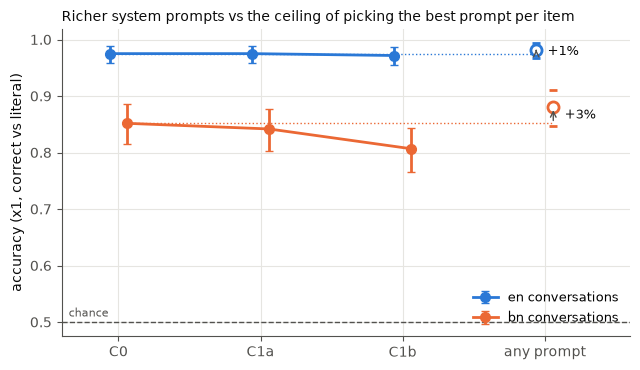

In [108]:

fig, ax = plt.subplots(figsize=(6.5, 3.8))
xs = {c: i for i, c in enumerate(conds + ["any prompt"])}
for j, l in enumerate(P):
    t = prompt_tab[prompt_tab["lang"] == l].set_index("cond")
    real = [c for c in conds if c in t.index]
    off = (j - 0.5) * 0.12
    ax.errorbar([xs[c] + off for c in real], t.loc[real, "acc"],
                yerr=[t.loc[real, "acc"] - t.loc[real, "ci_lo"], t.loc[real, "ci_hi"] - t.loc[real, "acc"]],
                color=LANG_COLOR[l], lw=2, marker="o", ms=7, capsize=3, label=f"{l} conversations")
    ceil, best = t.loc["any prompt"], t.loc[real, "acc"].max()
    ax.errorbar(xs["any prompt"] + off, ceil["acc"], yerr=[[ceil["acc"] - ceil["ci_lo"]], [ceil["ci_hi"] - ceil["acc"]]],
                color=LANG_COLOR[l], marker="o", ms=8, mfc="white", mew=2, capsize=3, lw=0)
    ax.hlines(best, xs[t.loc[real, "acc"].idxmax()] + off, xs["any prompt"] + off, colors=LANG_COLOR[l], ls=":", lw=1)
    ax.annotate("", xy=(xs["any prompt"] + off, ceil["acc"]), xytext=(xs["any prompt"] + off, best),
                arrowprops=dict(arrowstyle="->", color=MUTED, lw=1))
    ax.text(xs["any prompt"] + off + 0.08, (best + ceil["acc"]) / 2, f"+{ceil['acc'] - best:.0%}", color=INK, va="center", fontsize=9)
ax.axhline(0.5, color=MUTED, ls="--", lw=1); ax.text(-0.35, 0.505, "chance", color=MUTED, fontsize=8, va="bottom")
ax.set_xticks(list(xs.values()), list(xs.keys())); ax.set_xlim(-0.4, len(xs) - 0.4)
ax.set_ylabel("accuracy (x1, correct vs literal)")
ax.set_title("Richer system prompts vs the ceiling of picking the best prompt per item", color=INK, fontsize=10, loc="left")
ax.legend(frameon=False, loc="lower right", fontsize=9)
plt.tight_layout(); fig.savefig(FIG / "x8_ladder.png", dpi=150); plt.show()



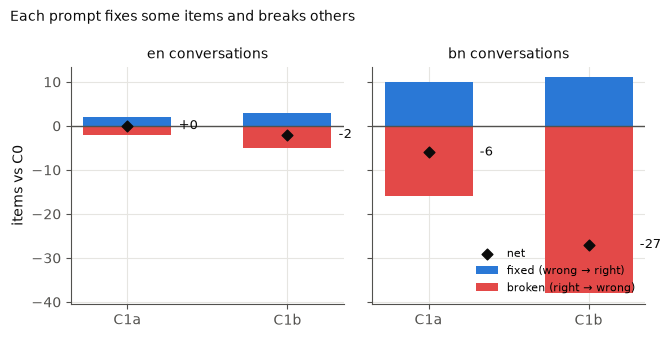

In [109]:
cmp = [c for c in conds if c != "C0"]
fig, axes = plt.subplots(1, len(P), figsize=(3.4 * len(P), 3.4), sharey=True, squeeze=False)
for ax, l in zip(axes[0], P):
    t = prompt_tab[(prompt_tab["lang"] == l) & prompt_tab["cond"].isin(cmp)].set_index("cond").reindex(cmp)
    x = np.arange(len(cmp))
    ax.bar(x, t["fixed_vs_C0"], width=0.55, color=GAIN, label="fixed (wrong → right)")
    ax.bar(x, -t["broken_vs_C0"], width=0.55, color=LOSS, label="broken (right → wrong)")
    ax.scatter(x, t["net_vs_C0"], color=INK, marker="D", s=30, zorder=3, label="net")
    for xi, v in zip(x, t["net_vs_C0"]):
        ax.text(xi + 0.32, v, f"{v:+.0f}", color=INK, va="center", fontsize=9)
    ax.axhline(0, color=MUTED, lw=1); ax.set_xticks(x, cmp); ax.set_title(f"{l} conversations", color=INK, fontsize=10)
axes[0, 0].set_ylabel("items vs C0")
axes[0, -1].legend(frameon=False, fontsize=8, loc="lower right")
fig.suptitle("Each prompt fixes some items and breaks others", color=INK, fontsize=10, x=0.02, ha="left")
plt.tight_layout(); fig.savefig(FIG / "x8_fixed_broken.png", dpi=150); plt.show()



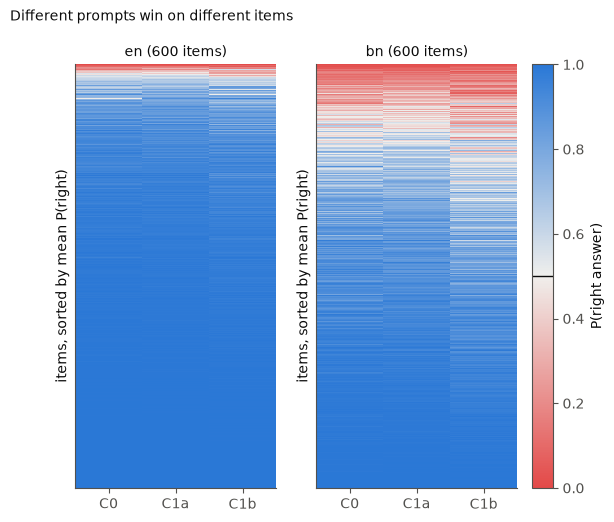

In [110]:
from matplotlib.colors import LinearSegmentedColormap
div = LinearSegmentedColormap.from_list("div", [LOSS, MID, GAIN])
fig, axes = plt.subplots(1, len(P), figsize=(2.6 * len(P) + 1, 5.5), squeeze=False)
for ax, l in zip(axes[0], P):
    M = pgold[l]
    M = M.loc[M.mean(axis=1).sort_values().index]
    im = ax.imshow(M.values, aspect="auto", cmap=div, vmin=0, vmax=1, interpolation="nearest")
    ax.set_xticks(range(M.shape[1]), M.columns); ax.set_yticks([]); ax.grid(False)
    ax.set_title(f"{l} ({len(M)} items)", color=INK, fontsize=10); ax.set_ylabel("items, sorted by mean P(right)")
cb = fig.colorbar(im, ax=axes[0].tolist(), fraction=0.05, pad=0.03); cb.set_label("P(right answer)")
cb.ax.axhline(0.5, color=INK, lw=1)
fig.suptitle("Different prompts win on different items", color=INK, fontsize=10, x=0.02, ha="left")
fig.savefig(FIG / "x8_item_map.png", dpi=150, bbox_inches="tight"); plt.show()



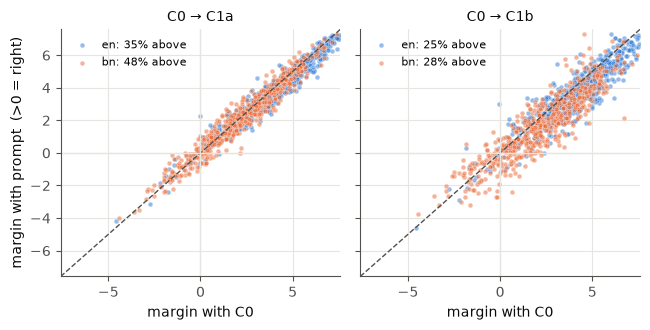

In [111]:
mg = {l: it.pivot_table(index="item_id", columns="cond", values="margin") for l, it in P.items()}
fig, axes = plt.subplots(1, len(cmp), figsize=(3.3 * len(cmp), 3.4), sharex=True, sharey=True, squeeze=False)
lim = np.nanpercentile(np.abs(pd.concat(mg.values()).values), 99)
for ax, c in zip(axes[0], cmp):
    for l in P:
        if c in mg[l]:
            ax.scatter(mg[l]["C0"], mg[l][c], s=12, alpha=0.5, color=LANG_COLOR[l], edgecolors="white", linewidths=0.4,
                       label=f"{l}: {(mg[l][c] > mg[l]['C0']).mean():.0%} above")
    ax.plot([-lim, lim], [-lim, lim], color=MUTED, lw=1, ls="--")
    ax.axhline(0, color=GRID, lw=1); ax.axvline(0, color=GRID, lw=1)
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_title(f"C0 → {c}", color=INK, fontsize=10)
    ax.set_xlabel("margin with C0"); ax.legend(frameon=False, fontsize=8, loc="upper left")
axes[0, 0].set_ylabel("margin with prompt  (>0 = right)")
plt.tight_layout(); fig.savefig(FIG / "x8_margin_shift.png", dpi=150); plt.show()

In [112]:
RUNS.keys()

dict_keys(['x1', 'x2', 'x3', 'x4', 'x5', 'x6', 'x7', 'x8', 'x8_bn', 'x8_en_pbn', 'x8_bn_pbn'])

,run,cond,acc,ci_lo,ci_hi,acc_db,pred_a,pred_b,fixed_vs_C0,broken_vs_C0,only_this_prompt,n,net_vs_C0
0,en prompt · en conv,C0,0.975,0.958,0.988,NaN,0.475,0.525,0.0,0.0,2.0,600,0.0
1,en prompt · en conv,C1a,0.975,0.958,0.988,NaN,0.478,0.522,2.0,2.0,1.0,600,0.0
2,en prompt · en conv,C1b,0.972,0.955,0.987,NaN,0.468,0.532,3.0,5.0,2.0,600,-2.0
3,en prompt · en conv,any prompt,0.982,0.967,0.993,NaN,NaN,NaN,NaN,NaN,NaN,600,NaN
4,en prompt · bn conv,C0,0.852,0.815,0.887,NaN,0.432,0.568,0.0,0.0,9.0,600,0.0
5,en prompt · bn conv,C1a,0.842,0.803,0.877,NaN,0.445,0.555,10.0,16.0,6.0,600,-6.0
6,en prompt · bn conv,C1b,0.807,0.765,0.843,NaN,0.420,0.580,11.0,38.0,7.0,600,-27.0
7,en prompt · bn conv,any prompt,0.880,0.847,0.910,NaN,NaN,NaN,NaN,NaN,NaN,600,NaN


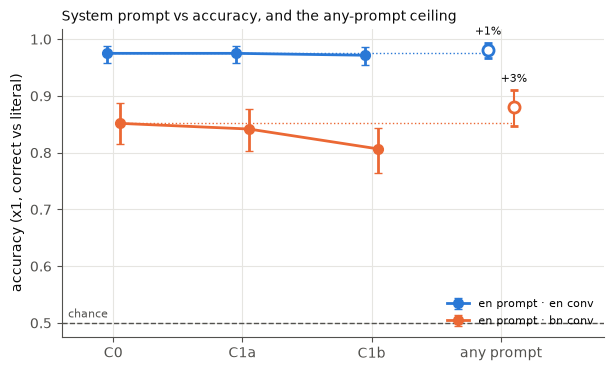

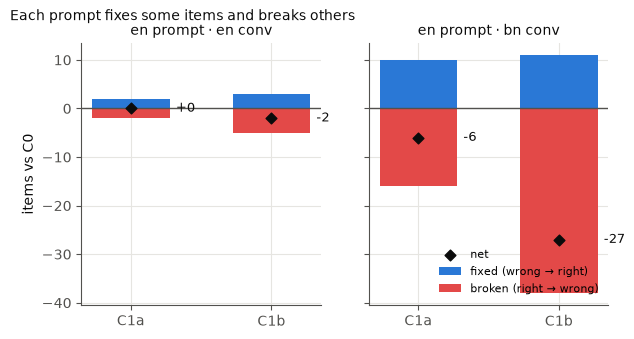

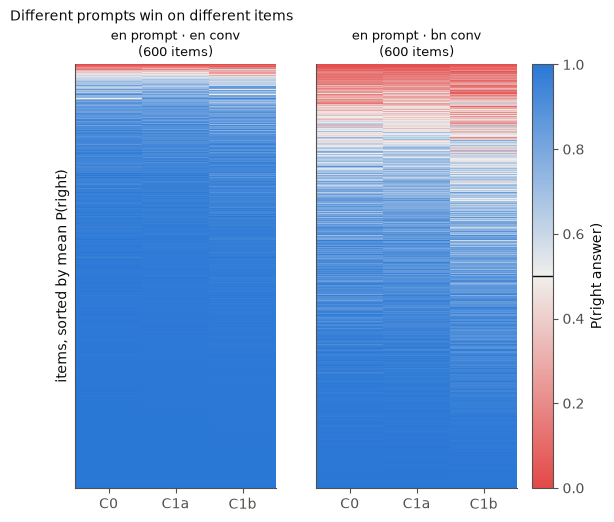

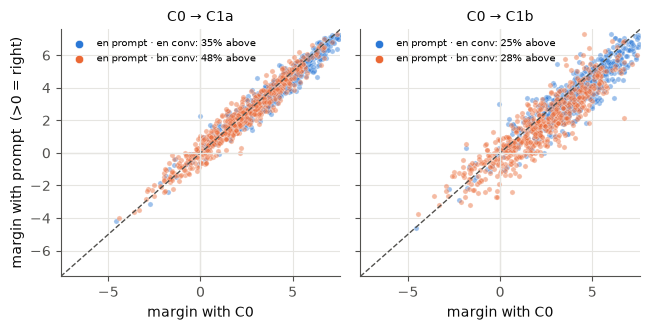

,run,cond,acc,ci_lo,ci_hi,acc_db,pred_a,pred_b,fixed_vs_C0,broken_vs_C0,only_this_prompt,n,net_vs_C0
0,bn prompt · en conv,C0,0.975,0.958,0.988,NaN,0.475,0.525,0.0,0.0,2.0,600,0.0
1,bn prompt · en conv,C1a,0.970,0.953,0.985,NaN,0.477,0.523,1.0,4.0,0.0,600,-3.0
2,bn prompt · en conv,C1b,0.978,0.963,0.992,NaN,0.482,0.518,7.0,5.0,6.0,600,2.0
3,bn prompt · en conv,any prompt,0.987,0.972,0.997,NaN,NaN,NaN,NaN,NaN,NaN,600,NaN
4,bn prompt · bn conv,C0,0.852,0.815,0.887,NaN,0.432,0.568,0.0,0.0,10.0,600,0.0
5,bn prompt · bn conv,C1a,0.863,0.827,0.897,NaN,0.463,0.537,19.0,12.0,9.0,600,7.0
6,bn prompt · bn conv,C1b,0.820,0.780,0.857,NaN,0.457,0.543,14.0,33.0,4.0,600,-19.0
7,bn prompt · bn conv,any prompt,0.890,0.857,0.920,NaN,NaN,NaN,NaN,NaN,NaN,600,NaN


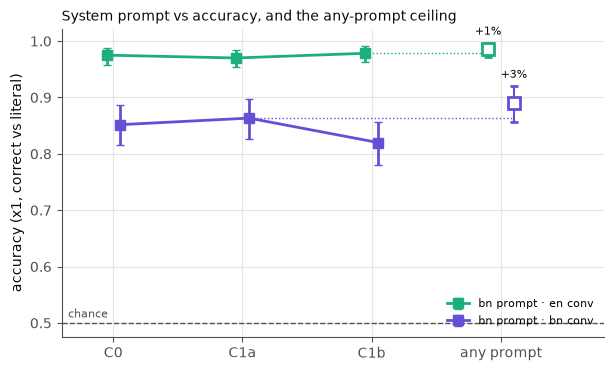

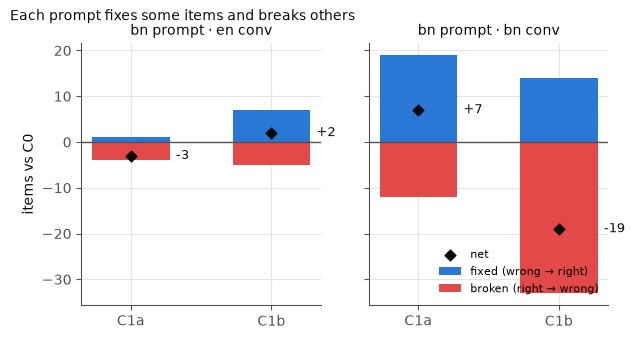

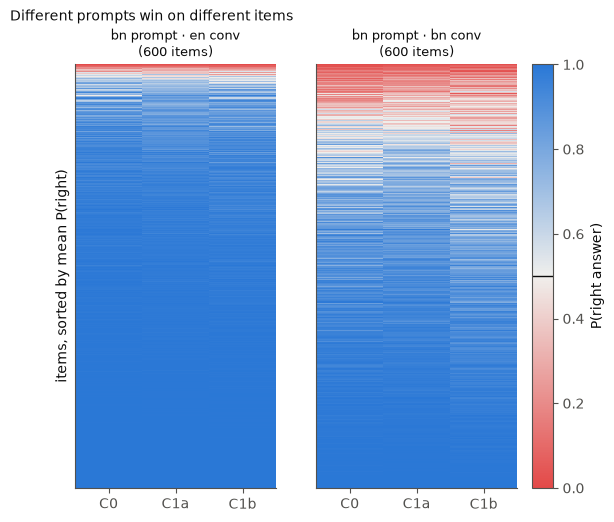

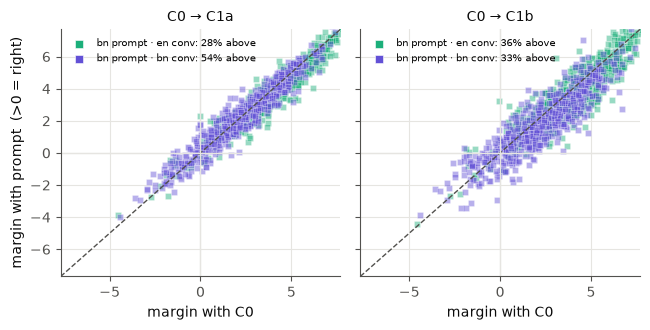

,run,cond,acc,ci_lo,ci_hi,acc_db,pred_a,pred_b,fixed_vs_C0,broken_vs_C0,only_this_prompt,n,net_vs_C0
0,bn prompt · bn conv,C0,0.852,0.815,0.887,NaN,0.432,0.568,0.0,0.0,10.0,600,0.0
1,bn prompt · bn conv,C1a,0.863,0.827,0.897,NaN,0.463,0.537,19.0,12.0,9.0,600,7.0
2,bn prompt · bn conv,C1b,0.820,0.780,0.857,NaN,0.457,0.543,14.0,33.0,4.0,600,-19.0
3,bn prompt · bn conv,any prompt,0.890,0.857,0.920,NaN,NaN,NaN,NaN,NaN,NaN,600,NaN
4,en prompt · bn conv,C0,0.852,0.815,0.887,NaN,0.432,0.568,0.0,0.0,9.0,600,0.0
5,en prompt · bn conv,C1a,0.842,0.803,0.877,NaN,0.445,0.555,10.0,16.0,6.0,600,-6.0
6,en prompt · bn conv,C1b,0.807,0.765,0.843,NaN,0.420,0.580,11.0,38.0,7.0,600,-27.0
7,en prompt · bn conv,any prompt,0.880,0.847,0.910,NaN,NaN,NaN,NaN,NaN,NaN,600,NaN


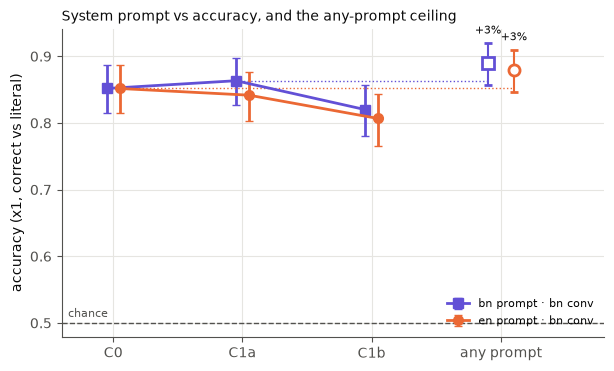

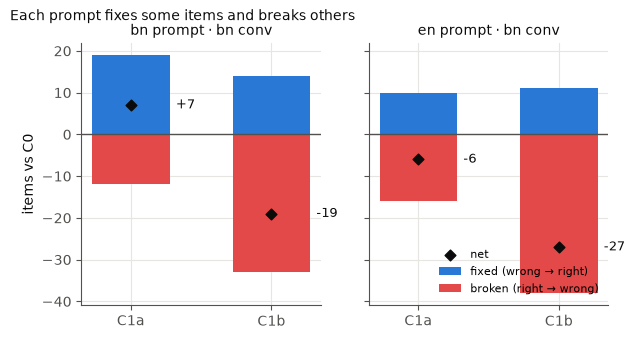

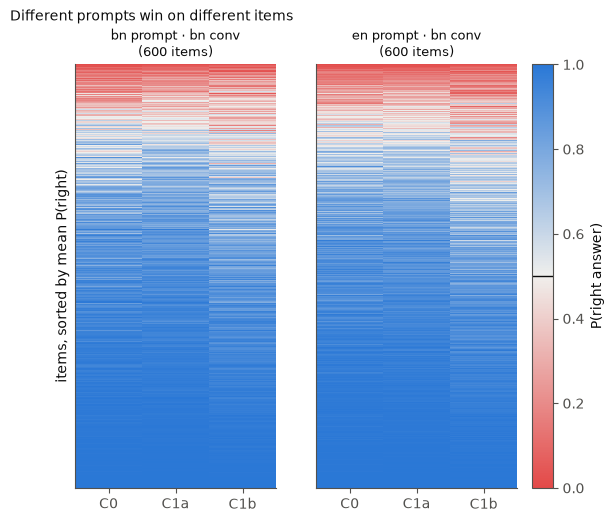

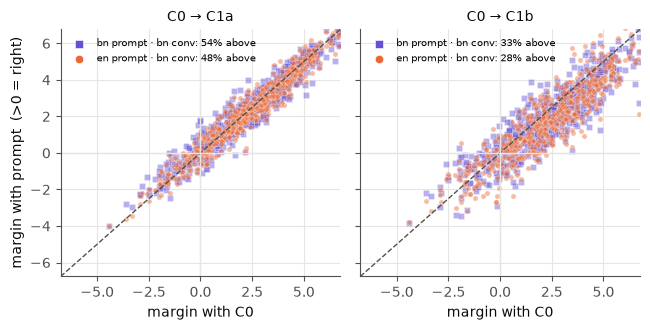

,run,cond,acc,ci_lo,ci_hi,acc_db,pred_a,pred_b,fixed_vs_C0,broken_vs_C0,only_this_prompt,n,net_vs_C0
0,en prompt · en conv,C0,0.975,0.958,0.988,NaN,0.475,0.525,0.0,0.0,2.0,600,0.0
1,en prompt · en conv,C1a,0.975,0.958,0.988,NaN,0.478,0.522,2.0,2.0,1.0,600,0.0
2,en prompt · en conv,C1b,0.972,0.955,0.987,NaN,0.468,0.532,3.0,5.0,2.0,600,-2.0
3,en prompt · en conv,any prompt,0.982,0.967,0.993,NaN,NaN,NaN,NaN,NaN,NaN,600,NaN
4,en prompt · bn conv,C0,0.852,0.815,0.887,NaN,0.432,0.568,0.0,0.0,9.0,600,0.0
5,en prompt · bn conv,C1a,0.842,0.803,0.877,NaN,0.445,0.555,10.0,16.0,6.0,600,-6.0
6,en prompt · bn conv,C1b,0.807,0.765,0.843,NaN,0.420,0.580,11.0,38.0,7.0,600,-27.0
7,en prompt · bn conv,any prompt,0.880,0.847,0.910,NaN,NaN,NaN,NaN,NaN,NaN,600,NaN
8,bn prompt · en conv,C0,0.975,0.958,0.988,NaN,0.475,0.525,0.0,0.0,2.0,600,0.0
9,bn prompt · en conv,C1a,0.970,0.953,0.985,NaN,0.477,0.523,1.0,4.0,0.0,600,-3.0


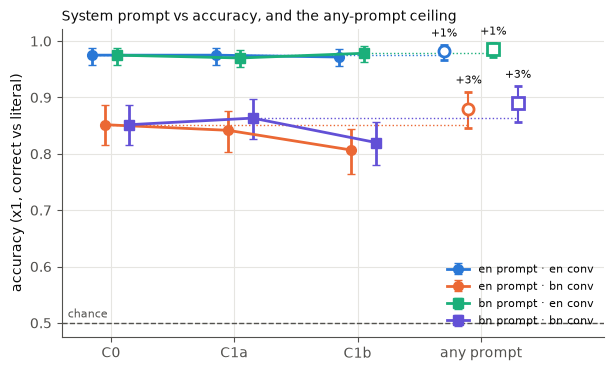

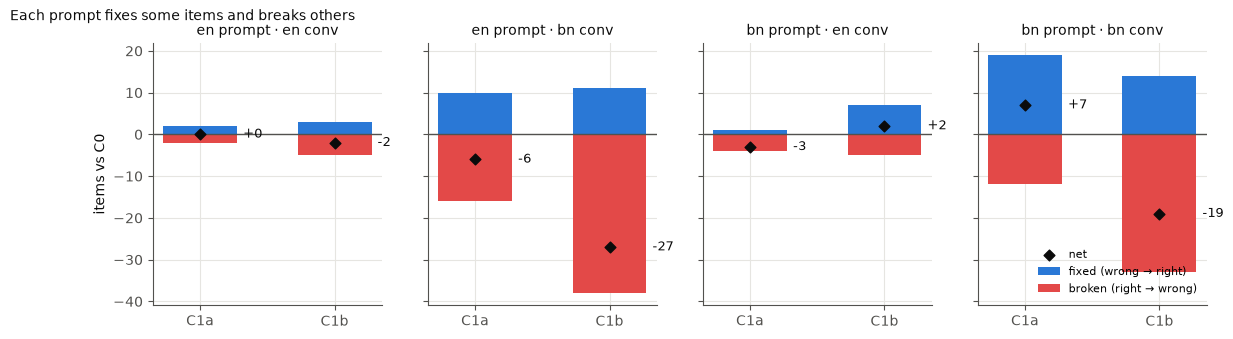

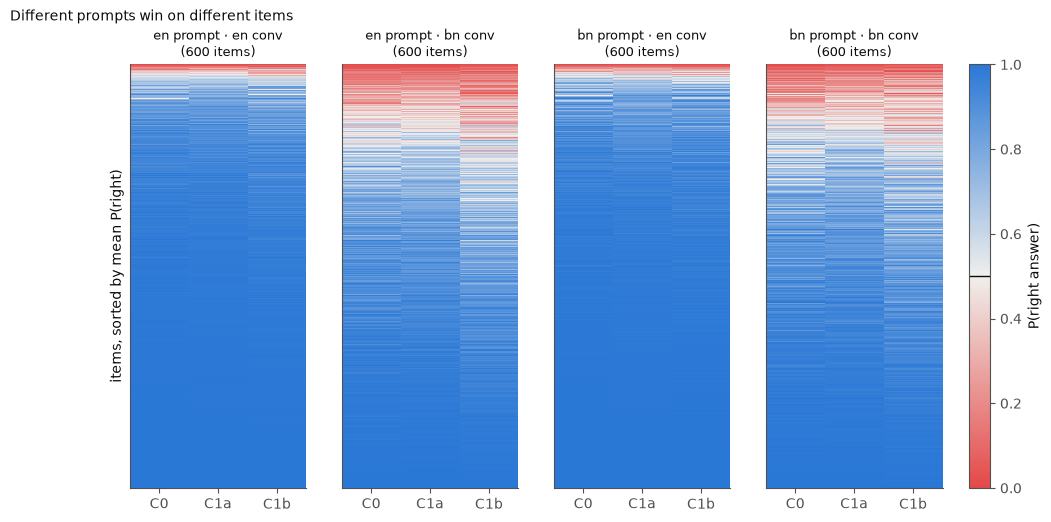

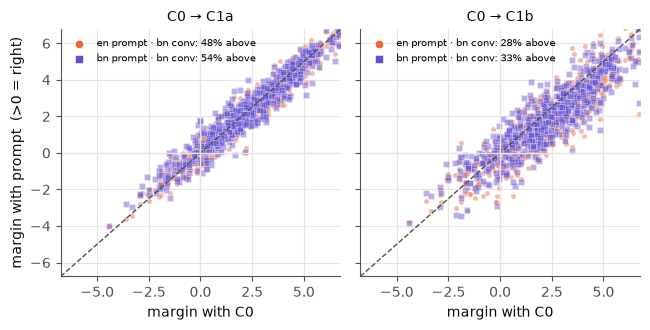

conv            bn     en
cond prompt              
C0   bn      0.852  0.975
     en      0.852  0.975
C1a  bn      0.863  0.970
     en      0.842  0.975
C1b  bn      0.820  0.978
     en      0.807  0.972


In [113]:
# RUNS = {"x1": x1_results_df, "x2": x2_results_df, "x3": x3_results_df, "x4": x4_results_df,
#         "x5": x5_results_df, "x6": x6_results_df, "x7": x7_results_df, "x8": x8_results_df,
#         "x8_bn": x8_bn_results_df, "x8_en_pbn": x8_en_pbn_results_df, "x8_bn_pdb": x8_bn_pbn_results_df}

# system prompts: English vs Bengali prompts
from matplotlib.colors import LinearSegmentedColormap

ORDER = ["C0", "C1a", "C1b", "C1c"]                    # C1c = GEPA prompt
C0_FROM = {"en conv": RUNS["x8"], "bn conv": RUNS["x8_bn"]}   # C0 = no system prompt, shared by both prompt languages
GAIN, LOSS, MID = "#2a78d6", "#e34948", "#f0efec"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True,
                     "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True, "font.size": 10})
STYLE = {"en prompt · en conv": ("#2a78d6", "o"),    # blue
         "en prompt · bn conv": ("#eb6834", "o"),    # orange
         "bn prompt · en conv": ("#1baf7a", "s"),    # aqua
         "bn prompt · bn conv": ("#6250d6", "s")}    # violet
def prompt_items(df):
    it = item_level(df)
    it["cond"] = it["label"].str.split("_").str[-1]
    return it[it["cond"].isin(ORDER)]

def prompt_plots(runs, tag):
    """runs = {"<en|bn> prompt · <en|bn> conv": df}. Colour = conversation language, marker = prompt language."""
    # color = {k: "#2a78d6" if k.endswith("en conv") else "#eb6834" for k in runs}
    # mark = {k: "s" if k.startswith("bn prompt") else "o" for k in runs}
    color = {k: STYLE[k][0] for k in runs}
    mark = {k: STYLE[k][1] for k in runs}
    P = {}
    for k, df in runs.items():
        it = prompt_items(df)
        if not (it["cond"] == "C0").any():                     # borrow C0 from the same conversation language
            c0 = prompt_items(C0_FROM[k.split("· ")[-1]])
            it = pd.concat([c0[c0["cond"] == "C0"], it], ignore_index=True)
        P[k] = it
    conds = [c for c in ORDER if any((P[k]["cond"] == c).any() for k in P)]
    right = {k: (it.pivot_table(index=["item_id", "proverb_id"], columns="cond", values="correct") >= 0.5)[
                 [c for c in conds if c in set(it["cond"])]] for k, it in P.items()}
    pgold = {k: it.pivot_table(index="item_id", columns="cond", values="p_gold")[right[k].columns] for k, it in P.items()}

    # table
    rows = []
    for k, it in P.items():
        R = right[k]
        for c in R.columns:
            g = it[it["cond"] == c]
            lo, hi = ci(g["correct"], g["proverb_id"])
            raw = sub(g["label"].iloc[0])
            rows.append({"run": k, "cond": c, "acc": g["correct"].mean(), "ci_lo": lo, "ci_hi": hi,
                         "acc_db": g["correct_db"].mean(), "pred_a": (raw["pred"] == "a").mean(),
                         "pred_b": (raw["pred"] == "b").mean(),
                         "fixed_vs_C0": int((R[c] & ~R["C0"]).sum()), "broken_vs_C0": int((~R[c] & R["C0"]).sum()),
                         "only_this_prompt": int((R[c] & ~R.drop(columns=c).any(axis=1)).sum()), "n": len(g)})
        any_right = R.any(axis=1).astype(float)
        lo, hi = ci(any_right, R.index.get_level_values("proverb_id"))
        rows.append({"run": k, "cond": "any prompt", "acc": any_right.mean(), "ci_lo": lo, "ci_hi": hi, "n": len(R)})
    tab = pd.DataFrame(rows)
    tab["net_vs_C0"] = tab["fixed_vs_C0"] - tab["broken_vs_C0"]
    # tab.to_csv(OUT / f"x8_{tag}_prompts.csv", index=False); 
    display(tab.round(3))

    # ladder + any-prompt ceiling
    fig, ax = plt.subplots(figsize=(7, 4))
    xs = {c: i for i, c in enumerate(conds + ["any prompt"])}
    for j, k in enumerate(P):
        t = tab[tab["run"] == k].set_index("cond")
        real = [c for c in conds if c in t.index]
        off = (j - (len(P) - 1) / 2) * 0.1
        ax.errorbar([xs[c] + off for c in real], t.loc[real, "acc"],
                    yerr=[t.loc[real, "acc"] - t.loc[real, "ci_lo"], t.loc[real, "ci_hi"] - t.loc[real, "acc"]],
                    color=color[k], lw=2, marker=mark[k], ms=7, capsize=3, label=k)
        ceil, best = t.loc["any prompt"], t.loc[real, "acc"].max()
        xc = xs["any prompt"] + (j - (len(P) - 1) / 2) * 0.2           # spread the ceiling markers wider
        ax.errorbar(xc, ceil["acc"], yerr=[[ceil["acc"] - ceil["ci_lo"]], [ceil["ci_hi"] - ceil["acc"]]],
                    color=color[k], marker=mark[k], ms=8, mfc="white", mew=2, capsize=3, ls="none", elinewidth=1.5)
        ax.hlines(best, xs[t.loc[real, "acc"].idxmax()] + off, xc, colors=color[k], ls=":", lw=1)
        ax.text(xc, ceil["ci_hi"] + 0.01, f"+{ceil['acc'] - best:.0%}", color=INK, ha="center", va="bottom", fontsize=8)
    ax.axhline(0.5, color=MUTED, ls="--", lw=1); ax.text(-0.35, 0.505, "chance", color=MUTED, fontsize=8, va="bottom")
    ax.set_xticks(list(xs.values()), list(xs.keys())); ax.set_xlim(-0.4, len(xs) - 0.4 + 0.1 * len(P))
    ax.set_ylabel("accuracy (x1, correct vs literal)")
    ax.set_title("System prompt vs accuracy, and the any-prompt ceiling", color=INK, fontsize=10, loc="left")
    ax.legend(frameon=False, loc="lower right", fontsize=8)
    # plt.tight_layout(); fig.savefig(FIG / f"x8_{tag}_ladder.png", dpi=150); 
    plt.show()

    # fixed / broken vs C0
    cmp = [c for c in conds if c != "C0"]
    fig, axes = plt.subplots(1, len(P), figsize=(3.4 * len(P), 3.4), sharey=True, squeeze=False)
    for ax, k in zip(axes[0], P):
        t = tab[(tab["run"] == k) & tab["cond"].isin(cmp)].set_index("cond").reindex(cmp)
        x = np.arange(len(cmp))
        ax.bar(x, t["fixed_vs_C0"], width=0.55, color=GAIN, label="fixed (wrong → right)")
        ax.bar(x, -t["broken_vs_C0"], width=0.55, color=LOSS, label="broken (right → wrong)")
        ax.scatter(x, t["net_vs_C0"], color=INK, marker="D", s=30, zorder=3, label="net")
        for xi, v in zip(x, t["net_vs_C0"]):
            ax.text(xi + 0.32, v, f"{v:+.0f}", color=INK, va="center", fontsize=9)
        ax.axhline(0, color=MUTED, lw=1); ax.set_xticks(x, cmp); ax.set_title(k, color=INK, fontsize=10)
    axes[0, 0].set_ylabel("items vs C0"); axes[0, -1].legend(frameon=False, fontsize=8, loc="lower right")
    fig.suptitle("Each prompt fixes some items and breaks others", color=INK, fontsize=10, x=0.02, ha="left")
    # plt.tight_layout(); fig.savefig(FIG / f"x8_{tag}_fixed_broken.png", dpi=150); 
    plt.show()

    # item x prompt map
    div = LinearSegmentedColormap.from_list("div", [LOSS, MID, GAIN])
    fig, axes = plt.subplots(1, len(P), figsize=(2.6 * len(P) + 1, 5.5), squeeze=False)
    for ax, k in zip(axes[0], P):
        M = pgold[k].loc[pgold[k].mean(axis=1).sort_values().index]
        im = ax.imshow(M.values, aspect="auto", cmap=div, vmin=0, vmax=1, interpolation="nearest")
        ax.set_xticks(range(M.shape[1]), M.columns); ax.set_yticks([]); ax.grid(False)
        ax.set_title(f"{k}\n({len(M)} items)", color=INK, fontsize=9)
    axes[0, 0].set_ylabel("items, sorted by mean P(right)")
    cb = fig.colorbar(im, ax=axes[0].tolist(), fraction=0.05, pad=0.03); cb.set_label("P(right answer)")
    cb.ax.axhline(0.5, color=INK, lw=1)
    fig.suptitle("Different prompts win on different items", color=INK, fontsize=10, x=0.02, ha="left")
    # fig.savefig(FIG / f"x8_{tag}_item_map.png", dpi=150, bbox_inches="tight"); 
    plt.show()

    # margin shift (at most 3 runs per panel, Bengali conversations first)
    # show = sorted(P, key=lambda k: not k.endswith("bn conv"))[:3]
    # mg = {k: P[k].pivot_table(index="item_id", columns="cond", values="margin") for k in show}
    # fig, axes = plt.subplots(1, len(cmp), figsize=(3.3 * len(cmp), 3.4), sharex=True, sharey=True, squeeze=False)
    # lim = np.nanpercentile(np.abs(pd.concat(mg.values()).values), 99)
    # for ax, c in zip(axes[0], cmp):
    #     for k in show:
    #         if c in mg[k]:
    #             ax.scatter(mg[k]["C0"], mg[k][c], s=12, alpha=0.5, color=color[k], marker=mark[k], edgecolors="white",
    #                        linewidths=0.4, label=f"{k}: {(mg[k][c] > mg[k]['C0']).mean():.0%} above")
    #     ax.plot([-lim, lim], [-lim, lim], color=MUTED, lw=1, ls="--")
    #     ax.axhline(0, color=GRID, lw=1); ax.axvline(0, color=GRID, lw=1)
    #     ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_title(f"C0 → {c}", color=INK, fontsize=10)
    #     ax.set_xlabel("margin with C0"); ax.legend(frameon=False, fontsize=7, loc="upper left")
    # axes[0, 0].set_ylabel("margin with prompt  (>0 = right)")
    # # plt.tight_layout(); fig.savefig(FIG / f"x8_{tag}_margin_shift.png", dpi=150);
    # plt.show()
    # return tab
    show = [k for k in P if k.endswith("bn conv")]
    show = show if len(show) >= 2 else list(P)[:3]
    mg = {k: P[k].pivot_table(index="item_id", columns="cond", values="margin") for k in show}
    fig, axes = plt.subplots(1, len(cmp), figsize=(3.3 * len(cmp), 3.4), sharex=True, sharey=True, squeeze=False)
    lim = np.nanpercentile(np.abs(pd.concat(mg.values()).values), 99)
    for ax, c in zip(axes[0], cmp):
        for k in show:
            if c in mg[k]:
                ax.scatter(mg[k]["C0"], mg[k][c], s=14, alpha=0.45, color=color[k], marker=mark[k], edgecolors="white",
                           linewidths=0.4, label=f"{k}: {(mg[k][c] > mg[k]['C0']).mean():.0%} above")
        ax.plot([-lim, lim], [-lim, lim], color=MUTED, lw=1, ls="--")
        ax.axhline(0, color=GRID, lw=1); ax.axvline(0, color=GRID, lw=1)
        ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_title(f"C0 → {c}", color=INK, fontsize=10)
        ax.set_xlabel("margin with C0")
        leg = ax.legend(frameon=False, fontsize=7, loc="upper left", markerscale=1.6)
        for h in getattr(leg, "legend_handles", getattr(leg, "legendHandles", [])):
            h.set_alpha(1)                                         # solid legend markers
    axes[0, 0].set_ylabel("margin with prompt  (>0 = right)")
    plt.tight_layout(); #fig.savefig(FIG / f"x8_{tag}_margin_shift.png", dpi=150); 
    plt.show()
    return tab

EN_P = {"en prompt · en conv": RUNS["x8"], "en prompt · bn conv": RUNS["x8_bn"]}
BN_P = {"bn prompt · en conv": RUNS["x8_en_pbn"], "bn prompt · bn conv": RUNS["x8_bn_pbn"]}
BN_COV = {"bn prompt · bn conv": RUNS["x8_bn_pbn"], "en prompt · bn conv": RUNS["x8_bn"]}
tab_en = prompt_plots(EN_P, "en_prompt")
tab_bn = prompt_plots(BN_P, "bn_prompt")
tab_bn_cov = prompt_plots(BN_COV, "bn_conv")
tab_all = prompt_plots({**EN_P, **BN_P}, "all")

# ---- 2x2 summary: prompt language x conversation language
t = tab_all[tab_all["cond"] != "any prompt"].copy()
t["prompt"], t["conv"] = t["run"].str.split().str[0], t["run"].str.split().str[-2]
print(t.pivot_table(index=["cond", "prompt"], columns="conv", values="acc").round(3))

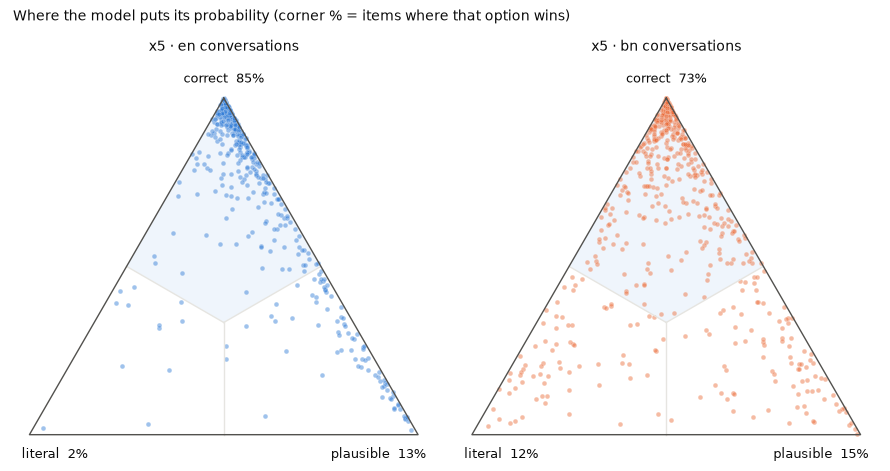

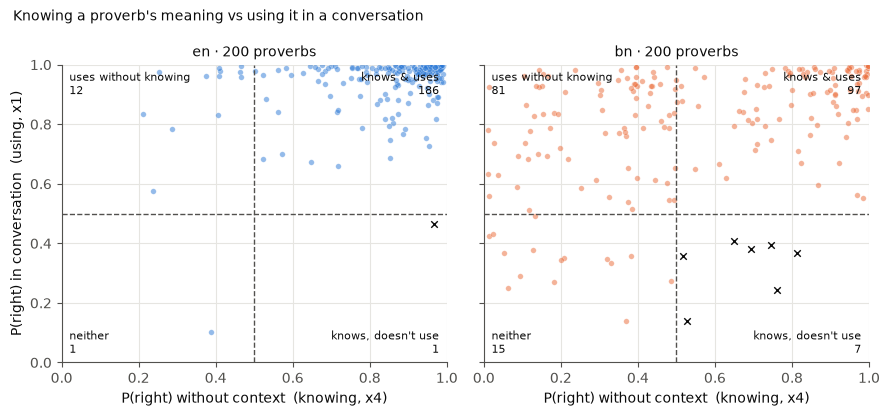

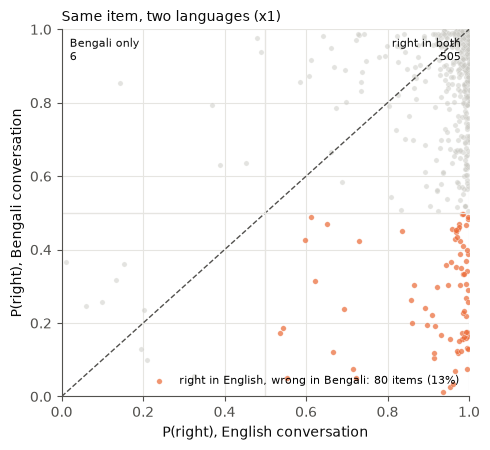

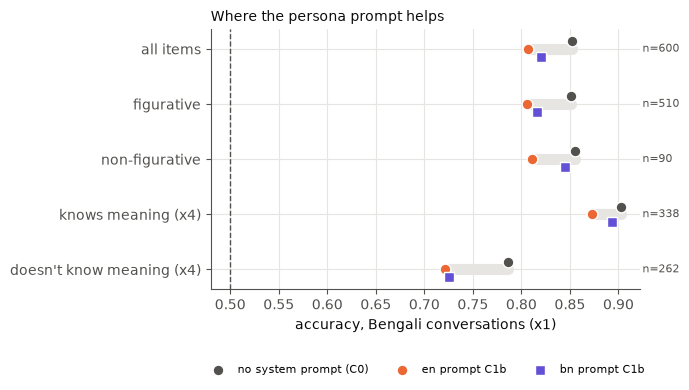

In [114]:
# ================================================================ 11. extra plots
CONV = {"en": "#2a78d6", "bn": "#eb6834"}              # conversation language
HI, LO_ = "#eb6834", "#c9c8c2"                         # highlight / background points

def key_probs(df, keys, none_last=False):
    """Add p_<key> columns (p_correct, p_literal, ...) by re-creating own_mcq's shuffle (seed 0 or df['seed'])."""
    out = []
    seeds = df["seed"] if "seed" in df else pd.Series(0, index=df.index)
    for (_, r), s in zip(df.iterrows(), seeds):
        k = list(keys)
        rng = random.Random(f"{r['item_id']}|{s}")
        if none_last:
            rest = [x for x in k if x != "none"]; rng.shuffle(rest); k = rest + ["none"]
        else:
            rng.shuffle(k)
        tot = sum(r[f"p_{L}"] for L in "abc"[:len(k)])
        out.append({f"p_{key}": r[f"p_{L}"] / tot for L, key in zip("abc", k)})
    return pd.concat([df.reset_index(drop=True), pd.DataFrame(out)], axis=1)

def corner_text(ax, x, y, text, ha, va):
    ax.text(x, y, text, transform=ax.transAxes, ha=ha, va=va, fontsize=8, color=INK)

# ---- 11a. where does the probability go? x5 items in the (correct, literal, plausible) triangle
TOP, BL, BR = np.array([0.5, np.sqrt(3) / 2]), np.array([0, 0]), np.array([1, 0])
fig, axes = plt.subplots(1, 2, figsize=(9, 4.4))
for ax, lang in zip(axes, ["en", "bn"]):
    d = key_probs(sub(f"x5_{lang}"), ("correct", "literal", "plausible"))
    xy = np.outer(d["p_correct"], TOP) + np.outer(d["p_literal"], BL) + np.outer(d["p_plausible"], BR)
    ctr = (TOP + BL + BR) / 3
    ax.fill([TOP[0], (TOP[0] + BL[0]) / 2, ctr[0], (TOP[0] + BR[0]) / 2],
            [TOP[1], (TOP[1] + BL[1]) / 2, ctr[1], (TOP[1] + BR[1]) / 2], color=GAIN, alpha=0.07, lw=0)
    for mid in [(TOP + BL) / 2, (TOP + BR) / 2, (BL + BR) / 2]:          # borders of "which option wins"
        ax.plot([ctr[0], mid[0]], [ctr[1], mid[1]], color=GRID, lw=1)
    ax.plot(*np.array([TOP, BL, BR, TOP]).T, color=MUTED, lw=1)
    ax.scatter(xy[:, 0], xy[:, 1], s=12, alpha=0.45, color=CONV[lang], edgecolors="white", linewidths=0.3)
    win = d[["p_correct", "p_literal", "p_plausible"]].idxmax(axis=1).value_counts(normalize=True)
    for (name, pt, dx, dy, ha) in [("correct", TOP, 0, 0.04, "center"), ("literal", BL, -0.02, -0.06, "left"),
                                  ("plausible", BR, 0.02, -0.06, "right")]:
        ax.text(pt[0] + dx, pt[1] + dy, f"{name}  {win.get('p_' + name, 0):.0%}", ha=ha, fontsize=9, color=INK)
    ax.set_aspect("equal"); ax.axis("off"); ax.set_title(f"x5 · {lang} conversations", color=INK, fontsize=10, pad=22)
fig.suptitle("Where the model puts its probability (corner % = items where that option wins)",
             color=INK, fontsize=10, x=0.02, ha="left", y=1.04)
plt.tight_layout(); fig.savefig(FIG / "x5_triangle.png", dpi=150, bbox_inches="tight"); plt.show()

# ---- 11b. knowing vs using per proverb: x4 (no context) vs x1 (in context)
fig, axes = plt.subplots(1, 2, figsize=(9, 4.2), sharey=True)
for ax, lang in zip(axes, ["en", "bn"]):
    k = item_level(sub(f"x4_{lang}"), ()).groupby("proverb_id")["p_gold"].mean()
    u = item_level(sub(f"x1_{lang}"), ()).groupby("proverb_id")["p_gold"].mean()
    m = pd.concat([k.rename("know"), u.rename("use")], axis=1).dropna()
    trap = (m["know"] > 0.5) & (m["use"] < 0.5)
    ax.scatter(m.loc[~trap, "know"], m.loc[~trap, "use"], s=16, alpha=0.5, color=CONV[lang], edgecolors="white", linewidths=0.3)
    ax.scatter(m.loc[trap, "know"], m.loc[trap, "use"], s=22, color=INK, marker="x", lw=1, label="knows, doesn't use")
    ax.axhline(0.5, color=MUTED, lw=1, ls="--"); ax.axvline(0.5, color=MUTED, lw=1, ls="--")
    q = lambda a, b: int(((m["know"] > 0.5) == a).mul((m["use"] > 0.5) == b).sum())
    corner_text(ax, 0.98, 0.98, f"knows & uses\n{q(True, True)}", "right", "top")
    corner_text(ax, 0.02, 0.98, f"uses without knowing\n{q(False, True)}", "left", "top")
    corner_text(ax, 0.02, 0.02, f"neither\n{q(False, False)}", "left", "bottom")
    corner_text(ax, 0.98, 0.02, f"knows, doesn't use\n{q(True, False)}", "right", "bottom")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_xlabel("P(right) without context  (knowing, x4)")
    ax.set_title(f"{lang} · {len(m)} proverbs", color=INK, fontsize=10)
axes[0].set_ylabel("P(right) in conversation  (using, x1)")
fig.suptitle("Knowing a proverb's meaning vs using it in a conversation", color=INK, fontsize=10, x=0.02, ha="left")
plt.tight_layout(); fig.savefig(FIG / "x4_vs_x1_proverbs.png", dpi=150); plt.show()

# ---- 11c. same item, two languages: x1 English vs Bengali conversation
m = item_level(sub("x1_en"), ()).merge(item_level(sub("x1_bn"), ())[["item_id", "p_gold"]], on="item_id", suffixes=("_en", "_bn"))
gap = (m["p_gold_en"] > 0.5) & (m["p_gold_bn"] < 0.5)
fig, ax = plt.subplots(figsize=(5, 4.6))
ax.scatter(m.loc[~gap, "p_gold_en"], m.loc[~gap, "p_gold_bn"], s=14, alpha=0.5, color=LO_, edgecolors="white", linewidths=0.3)
ax.scatter(m.loc[gap, "p_gold_en"], m.loc[gap, "p_gold_bn"], s=16, alpha=0.7, color=HI, edgecolors="white", linewidths=0.3,
           label=f"right in English, wrong in Bengali: {gap.sum()} items ({gap.mean():.0%})")
ax.plot([0, 1], [0, 1], color=MUTED, lw=1, ls="--")
ax.axhline(0.5, color=GRID, lw=1); ax.axvline(0.5, color=GRID, lw=1)
both = ((m["p_gold_en"] > 0.5) & (m["p_gold_bn"] > 0.5)).sum()
bn_only = ((m["p_gold_en"] < 0.5) & (m["p_gold_bn"] > 0.5)).sum()
corner_text(ax, 0.98, 0.98, f"right in both\n{both}", "right", "top")
corner_text(ax, 0.02, 0.98, f"Bengali only\n{bn_only}", "left", "top")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel("P(right), English conversation"); ax.set_ylabel("P(right), Bengali conversation")
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.set_title("Same item, two languages (x1)", color=INK, fontsize=10, loc="left")
plt.tight_layout(); fig.savefig(FIG / "x1_en_vs_bn.png", dpi=150); plt.show()

# ---- 11d. where does the persona help? C0 -> C1b on Bengali conversations, by subgroup
DUMB = {"no system prompt (C0)": ("x8_bn_C0", MUTED, "o"), "en prompt C1b": ("x8_bn_C1b", "#eb6834", "o"),
        "bn prompt C1b": ("x8_bn_pbn_C1b", "#6250d6", "s")}
DUMB = {k: v for k, v in DUMB.items() if (ALL["label"] == v[0]).any()}
know_bn = item_level(sub("x4_bn"), ()).set_index("item_id")["correct"] >= 0.5
groups = {"all items": lambda d: d.index == d.index, "figurative": lambda d: d["figurative"] == True,
          "non-figurative": lambda d: d["figurative"] == False,
          "knows meaning (x4)": lambda d: know_bn.reindex(d["item_id"]).fillna(False).to_numpy(),
          "doesn't know meaning (x4)": lambda d: ~know_bn.reindex(d["item_id"]).fillna(False).to_numpy()}
fig, ax = plt.subplots(figsize=(7, 0.55 * len(groups) + 1.4))
for i, (gname, f) in enumerate(groups.items()):
    accs = {}
    for name, (lab, col, mk) in DUMB.items():
        d = item_level(sub(lab), ())
        accs[name] = d[f(d)]["correct"].mean(); n = int(f(d).sum())
    ax.plot([min(accs.values()), max(accs.values())], [i, i], color=GRID, lw=8, zorder=1, solid_capstyle="round")
    for j, (name, (lab, col, mk)) in enumerate(DUMB.items()):
        ax.scatter(accs[name], i + (j - (len(DUMB) - 1) / 2) * 0.14, color=col, marker=mk, s=60, zorder=3,
                   edgecolors="white", linewidths=1, label=name if i == 0 else None)
    ax.text(1.005, i, f"n={n}", va="center", fontsize=8, color=MUTED, transform=ax.get_yaxis_transform())
ax.set_yticks(range(len(groups)), groups.keys()); ax.invert_yaxis()
ax.axvline(0.5, color=MUTED, ls="--", lw=1); ax.set_xlabel("accuracy, Bengali conversations (x1)")
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=3)
ax.set_title("Where the persona prompt helps", color=INK, fontsize=10, loc="left")
plt.tight_layout(); fig.savefig(FIG / "x8_bn_dumbbell.png", dpi=150, bbox_inches="tight"); plt.show()

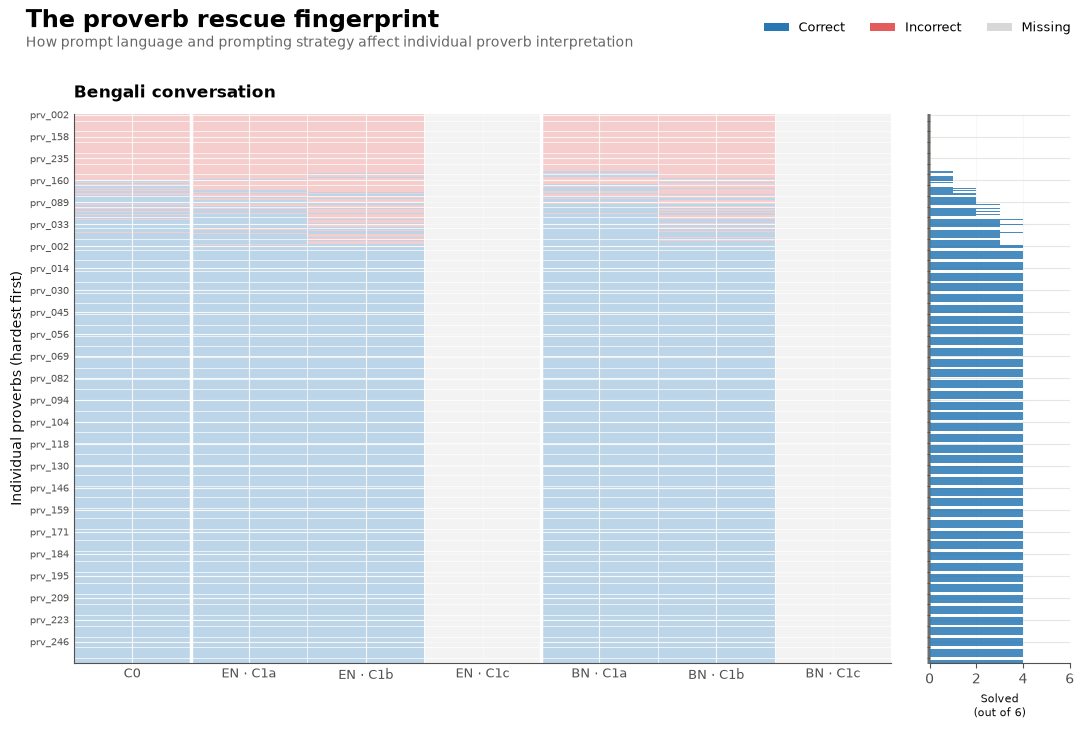

In [115]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

# Each conversation language has two prompt-language conditions.
CONFIG = {
    # "English conversation": {
    #     "C0": RUNS["x8"],
    #     "English prompt": RUNS["x8"],
    #     "Bengali prompt": RUNS["x8_en_pbn"],
    # },
    "Bengali conversation": {
        "C0": RUNS["x8_bn"],
        "English prompt": RUNS["x8_bn"],
        "Bengali prompt": RUNS["x8_bn_pbn"],
    },
}

STRATEGIES = ["C1a", "C1b", "C1c"]
PROMPT_COLS = (
    ["C0"] +
    [f"EN · {c}" for c in STRATEGIES] +
    [f"BN · {c}" for c in STRATEGIES]
)

def get_outcomes(df):
    it = item_level(df).copy()
    it["cond"] = it["label"].str.split("_").str[-1]

    result = {}
    for c in ["C0"] + STRATEGIES:
        g = it[it["cond"] == c]
        if len(g):
            # Aggregate multiple conversations belonging to a proverb
            s = g.groupby(["item_id", "proverb_id"])["correct"].mean()
            result[c] = (s >= 0.5).astype(float).where(s.notna())

    return result


def build_fingerprint(config):
    matrices = {}

    for conv, sources in config.items():
        columns = {}

        for prompt, df in sources.items():
            outcomes = get_outcomes(df)

            for c in (["C0"] if prompt == "C0" else STRATEGIES):
                if c in outcomes:
                    name = (
                        "C0" if prompt == "C0"
                        else f"{'EN' if prompt == 'English prompt' else 'BN'} · {c}"
                    )
                    columns[name] = outcomes[c]

        matrices[conv] = pd.DataFrame(columns).reindex(
            columns=PROMPT_COLS
        )

    # Same proverb ordering in both panels
    all_scores = pd.concat(
        [m for m in matrices.values()],
        axis=1
    )

    # Hardest proverbs first
    order = (
        all_scores.mean(axis=1)
        .sort_values(ascending=True, kind="stable")
        .index
    )

    return {
        k: v.reindex(order)
        for k, v in matrices.items()
    }


M = build_fingerprint(CONFIG)

# --- Publication-style visualization ---

BLUE = "#2878B5"       # Correct
RED = "#E45B5B"        # Incorrect
MISSING = "#D8D8D8"

cmap = ListedColormap([RED, MISSING, BLUE])
norm = BoundaryNorm([-0.5, 0.5, 1.5, 2.5], cmap.N)

n = len(next(iter(M.values())))
fig_h = max(7, min(15, n * 0.13 + 2))

fig = plt.figure(figsize=(12, fig_h))

gs = fig.add_gridspec(
    2, 2,
    width_ratios=[7, 1.2],
    height_ratios=[1, 1],
    hspace=0.35,
    wspace=0.08
)

for i, (conv, matrix) in enumerate(M.items()):
    ax = fig.add_subplot(gs[i, 0])
    side = fig.add_subplot(gs[i, 1], sharey=ax)

    data = matrix.to_numpy(dtype=float)

    # Encode missing values separately
    plot_data = np.where(np.isnan(data), 1, data * 2)

    ax.imshow(
        plot_data,
        aspect="auto",
        interpolation="nearest",
        cmap=cmap,
        norm=norm
    )

    # Column grouping
    ax.axvline(0.5, color="white", lw=2.5)
    ax.axvline(3.5, color="white", lw=2.5)

    ax.set_xticks(range(len(PROMPT_COLS)))
    ax.set_xticklabels(PROMPT_COLS, fontsize=9)

    ax.set_title(
        conv,
        loc="left",
        fontsize=12,
        fontweight="bold",
        pad=12
    )

    ax.set_ylabel("Individual proverbs (hardest first)")

    # Row labels: show all only for reasonably sized datasets
    if n <= 45:
        labels = [
            str(idx[1]) for idx in matrix.index
        ]
        ax.set_yticks(range(n))
        ax.set_yticklabels(labels, fontsize=6)
        ax.set_ylabel("Proverb ID")
    else:
        ticks = np.arange(0, n, max(1, n // 25))
        ax.set_yticks(ticks)
        ax.set_yticklabels(
            [str(matrix.index[j][1]) for j in ticks],
            fontsize=7
        )

    ax.tick_params(length=0)
    ax.set_xticks(np.arange(-0.5, len(PROMPT_COLS), 1), minor=True)
    ax.set_yticks(np.arange(-0.5, n, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=0.5)
    ax.tick_params(which="minor", bottom=False, left=False)

    # Right-hand side: number of prompt strategies solving each proverb
    solved = np.nansum(data[:, 1:], axis=1)

    side.barh(
        np.arange(n),
        solved,
        height=0.75,
        color=BLUE,
        alpha=0.85
    )

    side.set_xlim(0, 6)
    side.set_xticks([0, 2, 4, 6])
    side.set_xlabel("Solved\n(out of 6)", fontsize=8)
    side.tick_params(axis="y", left=False, labelleft=False)
    side.grid(axis="x", alpha=0.25)
    side.set_axisbelow(True)
    side.spines["left"].set_visible(False)
    side.spines["top"].set_visible(False)
    side.spines["right"].set_visible(False)

# Main title and explanation
fig.suptitle(
    "The proverb rescue fingerprint",
    x=0.08, y=0.99,
    ha="left",
    fontsize=17,
    fontweight="bold"
)

fig.text(
    0.08, 0.965,
    "How prompt language and prompting strategy affect "
    "individual proverb interpretation",
    fontsize=10,
    color="#666666"
)

legend = [
    Patch(facecolor=BLUE, label="Correct"),
    Patch(facecolor=RED, label="Incorrect"),
    Patch(facecolor=MISSING, label="Missing"),
]

fig.legend(
    handles=legend,
    loc="upper right",
    bbox_to_anchor=(0.96, 0.99),
    frameon=False,
    ncol=3,
    fontsize=9
)

plt.subplots_adjust(top=0.92, bottom=0.06, left=0.12, right=0.95)
plt.show()


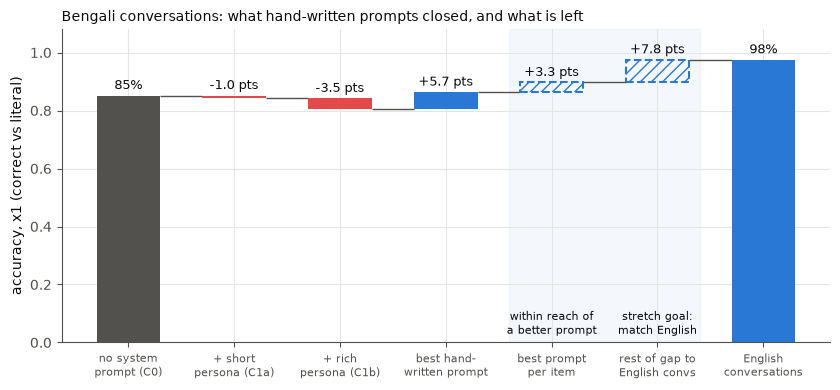

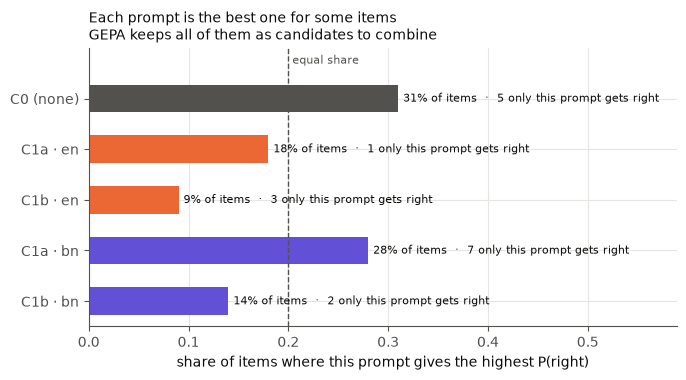

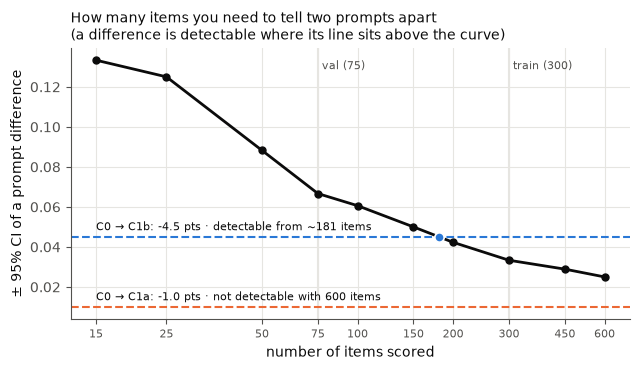

In [116]:
# ================================================================ 12. the case for GEPA (Bengali conversations)
BN_PROMPTS = {"C0 (none)": ("x8_bn_C0", MUTED), "C1a · en": ("x8_bn_C1a", "#eb6834"), "C1b · en": ("x8_bn_C1b", "#eb6834"),
              "C1a · bn": ("x8_bn_pbn_C1a", "#6250d6"), "C1b · bn": ("x8_bn_pbn_C1b", "#6250d6")}
BN_PROMPTS = {k: v for k, v in BN_PROMPTS.items() if (ALL["label"] == v[0]).any()}
EN_TARGET = "x8_en_C0"                                   # English conversations, no system prompt
acc_of = lambda label: item_level(sub(label), ())["correct"].mean()
items_bn = pd.concat({k: item_level(sub(lab), ()).set_index("item_id")[["correct", "p_gold", "proverb_id"]]
                      for k, (lab, _) in BN_PROMPTS.items()}, axis=1)

# ---- 12a. bridge: from no system prompt to the English-conversation level
a0, a1a, a1b = acc_of("x8_bn_C0"), acc_of("x8_bn_C1a"), acc_of("x8_bn_C1b")
best = max(acc_of(lab) for lab, _ in BN_PROMPTS.values())
ceiling = (items_bn.xs("correct", axis=1, level=1) >= 0.5).any(axis=1).mean()
target = acc_of(EN_TARGET)
steps = [("no system\nprompt (C0)", a0, "total"), ("+ short\npersona (C1a)", a1a - a0, "step"),
         ("+ rich\npersona (C1b)", a1b - a1a, "step"), ("best hand-\nwritten prompt", best - a1b, "step"),
         ("best prompt\nper item", ceiling - best, "target"), ("rest of gap to\nEnglish convs", target - ceiling, "target"),
         ("English\nconversations", target, "total")]
fig, ax = plt.subplots(figsize=(8.5, 4))
level = 0
for i, (name, v, kind) in enumerate(steps):
    if kind == "total":
        ax.bar(i, v, width=0.6, color=MUTED if i == 0 else "#2a78d6", zorder=2)
        ax.text(i, v + 0.012, f"{v:.0%}", ha="center", va="bottom", fontsize=9, color=INK); level = v
    else:
        lo, hi = sorted([level, level + v])
        style = dict(color=GAIN if v >= 0 else LOSS) if kind == "step" else \
                dict(facecolor="none", edgecolor=GAIN if v >= 0 else LOSS, ls="--", lw=1.5, hatch="///")
        ax.bar(i, hi - lo, bottom=lo, width=0.6, zorder=2, **style)
        ax.text(i, hi + 0.012, f"{v * 100:+.1f} pts", ha="center", va="bottom", fontsize=9, color=INK)
        level += v
    if i < len(steps) - 1:
        ax.hlines(level, i + 0.3, i + 0.7, color=MUTED, lw=1, zorder=1)
ax.axvspan(3.6, 5.4, color=GAIN, alpha=0.05, zorder=0)
ax.text(4, 0.03, "within reach of\na better prompt", ha="center", fontsize=8, color=INK)
ax.text(5, 0.03, "stretch goal:\nmatch English", ha="center", fontsize=8, color=INK)
ax.set_xticks(range(len(steps)), [s[0] for s in steps], fontsize=8); ax.set_ylim(0, 1.08)
ax.set_ylabel("accuracy, x1 (correct vs literal)")
ax.set_title("Bengali conversations: what hand-written prompts closed, and what is left", color=INK, fontsize=10, loc="left")
plt.tight_layout(); fig.savefig(FIG / "gepa_bridge.png", dpi=150); plt.show()

# ---- 12b. every prompt is the best prompt for some items (GEPA keeps each as a candidate)
P_ = items_bn.xs("p_gold", axis=1, level=1)
R_ = items_bn.xs("correct", axis=1, level=1) >= 0.5
best_share = P_.idxmax(axis=1).value_counts(normalize=True).reindex(P_.columns).fillna(0)
only = (R_ & (R_.sum(axis=1) == 1).to_numpy()[:, None]).sum()
fig, ax = plt.subplots(figsize=(7, 0.5 * len(P_.columns) + 1.4))
y = np.arange(len(P_.columns))
ax.barh(y, best_share, height=0.55, color=[BN_PROMPTS[k][1] for k in P_.columns], zorder=2)
ax.axvline(1 / len(P_.columns), color=MUTED, ls="--", lw=1)
ax.text(1 / len(P_.columns), -0.75, " equal share", color=MUTED, fontsize=8, va="center")
for yi, k in zip(y, P_.columns):
    ax.text(best_share[k] + 0.005, yi, f"{best_share[k]:.0%} of items  ·  {only[k]} only this prompt gets right",
            va="center", fontsize=8, color=INK)
ax.set_yticks(y, P_.columns); ax.set_ylim(len(y) - 0.5, -1); ax.set_xlim(0, max(best_share.max() * 1.9, 0.5))
ax.set_xlabel("share of items where this prompt gives the highest P(right)")
ax.set_title("Each prompt is the best one for some items\nGEPA keeps all of them as candidates to combine",
             color=INK, fontsize=10, loc="left")
plt.tight_layout(); fig.savefig(FIG / "gepa_best_prompt_per_item.png", dpi=150); plt.show()

# ---- 12c. eval budget: how many items to tell two prompts apart
d_full = (items_bn[("C1b · en", "correct")] - items_bn[("C0 (none)", "correct")]).to_numpy()
prov = items_bn[("C0 (none)", "proverb_id")].to_numpy()
ids, inv = np.unique(prov, return_inverse=True)
s, c = np.bincount(inv, d_full), np.bincount(inv)
per_prov = len(d_full) / len(ids)
rng = np.random.default_rng(0)
ns = [n for n in (15, 25, 50, 75, 100, 150, 200, 300, 450, 600) if n <= len(d_full)]
half = []
for n in ns:
    k = max(2, round(n / per_prov))
    pick = rng.integers(0, len(ids), (2000, k))
    boot = s[pick].sum(1) / c[pick].sum(1)
    half.append((np.percentile(boot, 97.5) - np.percentile(boot, 2.5)) / 2)
# fig, ax = plt.subplots(figsize=(6.5, 3.8))
# ax.plot(ns, half, color=INK, lw=2, marker="o", ms=5, zorder=3)
# effects = {"C0 → C1b": d_full.mean(), "C0 → C1a": acc_of("x8_bn_C1a") - acc_of("x8_bn_C0")}
# for (name, e), col in zip(effects.items(), [GAIN, "#eb6834"]):
#     ax.axhline(abs(e), color=col, lw=1.5, ls="--")
#     ax.text(ns[-1], abs(e), f"{name}: {e * 100:+.1f} pts", color=INK, fontsize=8, ha="right", va="bottom")
# for n, name in [(75, "val (75)"), (300, "train (300)")]:
#     if n <= ns[-1]:
#         ax.axvline(n, color=GRID, lw=1.5, zorder=1)
#         ax.text(n, max(half), f" {name}", fontsize=8, color=MUTED, va="top")
# ax.set_xscale("log"); ax.set_xticks(ns, [str(n) for n in ns], fontsize=8); ax.minorticks_off()
# ax.set_xlabel("number of items scored"); ax.set_ylabel("± 95% CI of a prompt difference")
# ax.set_title("How many items you need to tell two prompts apart\n(a difference is detectable where its line sits above the curve)",
#              color=INK, fontsize=10, loc="left")
# plt.tight_layout(); fig.savefig(FIG / "gepa_eval_budget.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(ns, half, color=INK, lw=2, marker="o", ms=5, zorder=3)
effects = {"C0 → C1b": d_full.mean(), "C0 → C1a": acc_of("x8_bn_C1a") - acc_of("x8_bn_C0")}
for (name, e), col in zip(effects.items(), [GAIN, "#eb6834"]):
    ax.axhline(abs(e), color=col, lw=1.5, ls="--", zorder=2)
    below = [i for i, h in enumerate(half) if h < abs(e)]
    if not below:
        note = f"not detectable with {ns[-1]} items"
    else:
        i = below[0]
        n_star = ns[0] if i == 0 else np.exp(np.interp(abs(e), [half[i], half[i - 1]],
                                                       [np.log(ns[i]), np.log(ns[i - 1])]))
        ax.scatter(n_star, abs(e), color=col, s=45, zorder=4, edgecolors="white", linewidths=1.2)
        note = f"detectable from ~{n_star:.0f} items"
    left = abs(half[0] - abs(e)) > abs(half[-1] - abs(e))          # label on the side where the curve is far away
    ax.text(ns[0] if left else ns[-1], abs(e) + 0.002, f"{name}: {e * 100:+.1f} pts · {note}",
            color=INK, fontsize=8, ha="left" if left else "right", va="bottom")
for n, name in [(75, "val (75)"), (300, "train (300)")]:
    if n <= ns[-1]:
        ax.axvline(n, color=GRID, lw=1.5, zorder=1)
        ax.text(n, max(half), f" {name}", fontsize=8, color=MUTED, va="top")
ax.set_xscale("log"); ax.set_xticks(ns, [str(n) for n in ns], fontsize=8); ax.minorticks_off()
ax.set_xlabel("number of items scored"); ax.set_ylabel("± 95% CI of a prompt difference")
ax.set_title("How many items you need to tell two prompts apart\n(a difference is detectable where its line sits above the curve)",
             color=INK, fontsize=10, loc="left")
plt.tight_layout(); fig.savefig(FIG / "gepa_eval_budget.png", dpi=150); plt.show()

In [117]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.colors import to_rgba

# --------------------------------------------------
# 1. Experimental configuration
# --------------------------------------------------

BASELINE = RUNS["x8_bn"]

PROMPTS = {
    "EN": RUNS["x8_bn"],
    "BN": RUNS["x8_bn_pbn"],
}

# STRATEGIES = ["C1a", "C1b", "C1c"]
STRATEGIES = ["C1a", "C1b"]

CONFIG = {
    "C0": (BASELINE, "C0"),
    **{
        f"{lang} · {cond}": (df, cond)
        for lang, df in PROMPTS.items()
        for cond in STRATEGIES
    }
}

COLORS = {
    "C0": "#555555",
    "EN · C1a": "#8B9DC3",
    "EN · C1b": "#E07A5F",
    "EN · C1c": "#277DA1",
    "BN · C1a": "#B07AA1",
    "BN · C1b": "#59A14F",
    "BN · C1c": "#E3A32D",
}

INK = "#202124"
MUTED = "#666666"
GRID = "#E6E6E6"

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": MUTED,
    "axes.labelcolor": INK,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.7,
    "axes.axisbelow": True,
    "font.size": 10,
})


# --------------------------------------------------
# 2. Extract proverb-level observations
# --------------------------------------------------

def extract_condition(df, cond):
    it = item_level(df).copy()

    it["cond"] = it["label"].str.split("_").str[-1]
    g = it[it["cond"] == cond].copy()

    if g.empty:
        raise ValueError(f"No observations found for {cond}")

    # Aggregate repeated conversations for each proverb
    grouped = g.groupby(
        ["item_id", "proverb_id"],
        sort=False
    )

    out = grouped.agg(
        correct=("correct", "mean"),
        margin=("margin", "mean"),
        p_gold=("p_gold", "mean"),
    )

    # Majority correctness
    out["right"] = out["correct"] >= 0.5

    return out


D = {
    name: extract_condition(df, cond)
    for name, (df, cond) in CONFIG.items()
}

# Align all conditions to the same proverb observations
INDEX = D["C0"].index

for name in D:
    D[name] = D[name].reindex(INDEX)

# Binary outcome matrix
RIGHT = pd.DataFrame({
    name: d["right"]
    for name, d in D.items()
}).astype("boolean")

# Margin matrix
MARGIN = pd.DataFrame({
    name: d["margin"]
    for name, d in D.items()
})

# Gold-answer probability matrix
PGOLD = pd.DataFrame({
    name: d["p_gold"]
    for name, d in D.items()
})

PROMPT_NAMES = list(PROMPTS.keys())
CONDITIONS = list(CONFIG.keys())

print("Proverb observations:", len(INDEX))
print("Conditions:", CONDITIONS)

display(
    pd.DataFrame({
        "accuracy": RIGHT.mean(),
        "n": RIGHT.notna().sum()
    }).round(3)
)


Proverb observations: 600
Conditions: ['C0', 'EN · C1a', 'EN · C1b', 'BN · C1a', 'BN · C1b']


,accuracy,n
C0,0.852,600
EN · C1a,0.842,600
EN · C1b,0.807,600
BN · C1a,0.863,600
BN · C1b,0.82,600


TypeError: Choicelist and default value do not have a common dtype: The DType <class 'numpy.dtypes._PyLongDType'> could not be promoted by <class 'numpy.dtypes.StrDType'>. This means that no common DType exists for the given inputs. For example they cannot be stored in a single array unless the dtype is `object`. The full list of DTypes is: (<class 'numpy.dtypes.StrDType'>, <class 'numpy.dtypes.StrDType'>, <class 'numpy.dtypes.StrDType'>, <class 'numpy.dtypes.StrDType'>, <class 'numpy.dtypes._PyLongDType'>)

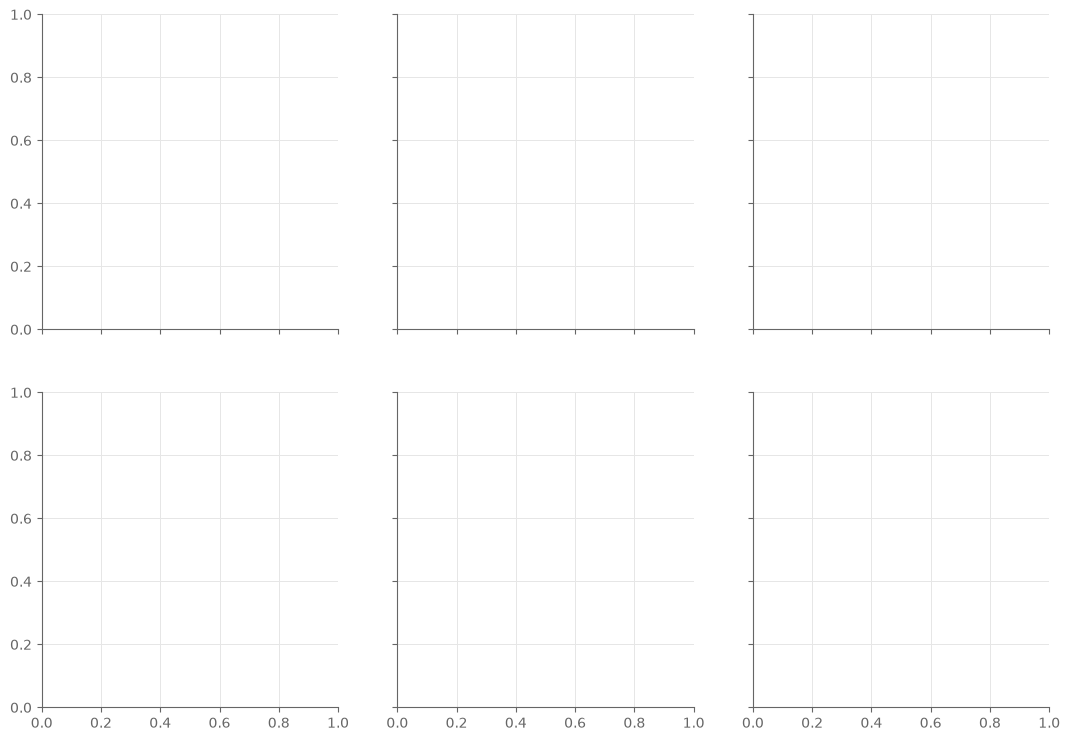

In [118]:

# --------------------------------------------------
# PLOT 1: CONFIDENCE MIGRATION
# --------------------------------------------------

fig, axes = plt.subplots(
    2, 3,
    figsize=(13, 9),
    sharex=True,
    sharey=True
)

# Common axis limits
valid = pd.concat(
    [MARGIN["C0"]] +
    [MARGIN[c] for c in CONDITIONS if c != "C0"]
).dropna()

lim = np.nanpercentile(np.abs(valid), 98)
lim = max(lim, 0.1)

STATE_COLORS = {
    "Both correct": "#2878B5",
    "Rescued": "#36A269",
    "Broken": "#E45756",
    "Both wrong": "#A0A0A0",
}

for i, lang in enumerate(["EN", "BN"]):
    for j, strategy in enumerate(STRATEGIES):

        ax = axes[i, j]
        name = f"{lang} · {strategy}"

        x = MARGIN["C0"]
        y = MARGIN[name]

        base_right = RIGHT["C0"].astype("boolean")
        new_right = RIGHT[name].astype("boolean")

        valid_mask = x.notna() & y.notna() & base_right.notna() & new_right.notna()

        x = x[valid_mask]
        y = y[valid_mask]

        b = base_right[valid_mask].astype(bool)
        p = new_right[valid_mask].astype(bool)

        states = np.select(
            [
                b & p,
                ~b & p,
                b & ~p,
                ~b & ~p,
            ],
            [
                "Both correct",
                "Rescued",
                "Broken",
                "Both wrong",
            ]
        )

        for state, color in STATE_COLORS.items():
            mask = states == state

            ax.scatter(
                x[mask],
                y[mask],
                s=35,
                alpha=0.75,
                color=color,
                edgecolors="white",
                linewidths=0.4,
                label=state if (i == 0 and j == 0) else None
            )

        # No-change diagonal
        ax.plot(
            [-lim, lim],
            [-lim, lim],
            color=INK,
            linestyle="--",
            linewidth=1,
            alpha=0.6
        )

        # Zero-margin boundaries
        ax.axhline(0, color=GRID, linewidth=1)
        ax.axvline(0, color=GRID, linewidth=1)

        # Improvement arrow
        ax.annotate(
            "Higher GEPA margin",
            xy=(0.75, 0.92),
            xycoords="axes fraction",
            ha="center",
            fontsize=8,
            color=MUTED
        )

        ax.set_xlim(-lim, lim)
        ax.set_ylim(-lim, lim)

        ax.set_title(
            f"{lang} prompt · {strategy}",
            loc="left",
            fontweight="bold",
            fontsize=11
        )

        if i == 1:
            ax.set_xlabel("C0 margin")

        if j == 0:
            ax.set_ylabel("Prompted margin")

handles = [
    Patch(facecolor=color, label=label)
    for label, color in STATE_COLORS.items()
]

fig.legend(
    handles=handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.96),
    ncol=4,
    frameon=False
)

fig.suptitle(
    "Confidence migration: baseline vs prompted reasoning",
    x=0.06,
    y=1.01,
    ha="left",
    fontsize=16,
    fontweight="bold"
)

fig.text(
    0.06, 0.975,
    "Bengali conversations · Each point represents one proverb",
    fontsize=10,
    color=MUTED
)

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()


In [119]:

# --------------------------------------------------
# PLOT 2: PROMPT COMPLEMENTARITY (UPSET)
# --------------------------------------------------

SETS = [
    "EN · C1a", "EN · C1b", "EN · C1c",
    "BN · C1a", "BN · C1b", "BN · C1c",
]

# Only use observations with all six prompt outcomes
U = RIGHT[SETS].dropna().astype(bool)

# Each row becomes an exact success/failure combination
patterns = U.apply(
    lambda row: tuple(row.astype(int)),
    axis=1
)

intersections = (
    patterns.value_counts()
    .rename("count")
    .reset_index()
)

intersections.columns = ["pattern", "count"]

# Sort by frequency, show the largest intersections
intersections = intersections.head(15).reset_index(drop=True)

fig = plt.figure(figsize=(13, 7))

gs = fig.add_gridspec(
    2, 1,
    height_ratios=[3, 2],
    hspace=0.05
)

ax_bar = fig.add_subplot(gs[0])
ax_mat = fig.add_subplot(gs[1], sharex=ax_bar)

x = np.arange(len(intersections))

# Intersection size bars
bars = ax_bar.bar(
    x,
    intersections["count"],
    width=0.7,
    color="#4C78A8",
    edgecolor="white"
)

for bar, count in zip(bars, intersections["count"]):
    ax_bar.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.3,
        str(count),
        ha="center",
        va="bottom",
        fontsize=9
    )

ax_bar.set_ylabel("Number of proverbs")
ax_bar.set_title(
    "Which prompt configurations solve the same proverbs?",
    loc="left",
    fontsize=14,
    fontweight="bold"
)

ax_bar.spines["bottom"].set_visible(False)
ax_bar.tick_params(axis="x", bottom=False, labelbottom=False)

# Intersection matrix
ax_mat.set_ylim(-0.5, len(SETS) - 0.5)
ax_mat.invert_yaxis()

ax_mat.set_yticks(range(len(SETS)))
ax_mat.set_yticklabels(SETS, fontsize=9)

for xi, row in enumerate(intersections["pattern"]):
    active = np.where(np.array(row) == 1)[0]

    # Background dots
    ax_mat.scatter(
        np.full(len(SETS), xi),
        np.arange(len(SETS)),
        color="#D9D9D9",
        s=28,
        zorder=1
    )

    # Connected intersection dots
    if len(active) > 1:
        ax_mat.plot(
            [xi, xi],
            [active.min(), active.max()],
            color="#777777",
            linewidth=1.5,
            zorder=2
        )

    if len(active):
        ax_mat.scatter(
            np.full(len(active), xi),
            active,
            color="#222222",
            s=45,
            zorder=3
        )

ax_mat.set_xticks(x)
ax_mat.set_xticklabels(
    [str(i + 1) for i in x],
    fontsize=8
)

ax_mat.set_xlabel("Intersection rank")
ax_mat.grid(False)

for spine in ["top", "right", "left"]:
    ax_mat.spines[spine].set_visible(False)

fig.suptitle(
    "Prompt complementarity across Bengali conversations",
    x=0.07,
    y=0.98,
    ha="left",
    fontsize=16,
    fontweight="bold"
)

fig.text(
    0.07, 0.945,
    "Each intersection represents an exact combination of successful prompts",
    fontsize=10,
    color=MUTED
)

plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

# Inspect the actual combinations
display(intersections)


KeyError: "['EN · C1c', 'BN · C1c'] not in index"

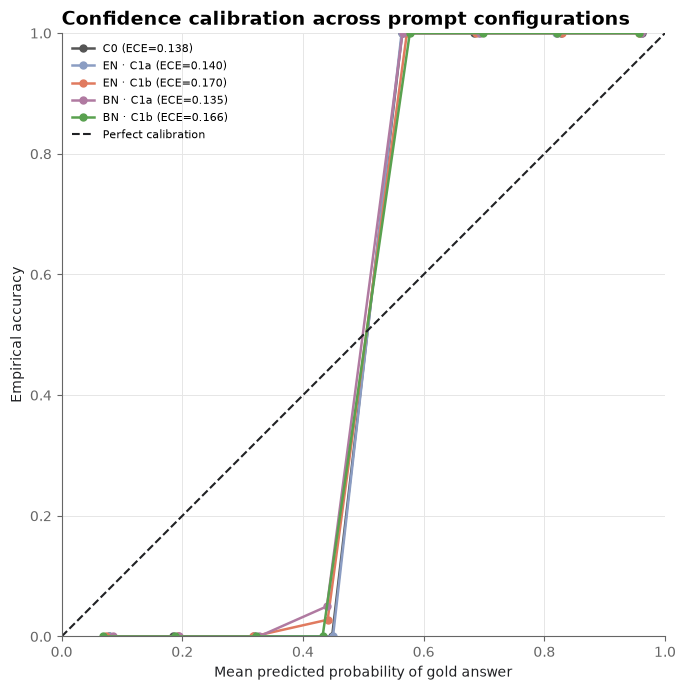

,condition,ECE,Brier,n
3,BN · C1a,0.1353,0.0378,600
0,C0,0.1378,0.0390,600
1,EN · C1a,0.1404,0.0392,600
4,BN · C1b,0.1659,0.0487,600
2,EN · C1b,0.1699,0.0515,600


In [120]:

# --------------------------------------------------
# PLOT 3: CONFIDENCE CALIBRATION
# --------------------------------------------------

from sklearn.metrics import brier_score_loss

N_BINS = 8
BIN_EDGES = np.linspace(0, 1, N_BINS + 1)

fig, ax = plt.subplots(figsize=(8, 7))

ece_results = []

for name in CONDITIONS:

    temp = pd.DataFrame({
        "confidence": PGOLD[name],
        "correct": RIGHT[name].astype("float")
    }).dropna()

    temp = temp[
        temp["confidence"].between(0, 1)
    ]

    temp["bin"] = pd.cut(
        temp["confidence"],
        bins=BIN_EDGES,
        include_lowest=True
    )

    calibration = (
        temp.groupby("bin", observed=False)
        .agg(
            confidence=("confidence", "mean"),
            accuracy=("correct", "mean"),
            n=("correct", "size")
        )
        .dropna()
    )

    # Expected calibration error
    ece = np.sum(
        calibration["n"] / len(temp) *
        np.abs(
            calibration["accuracy"] -
            calibration["confidence"]
        )
    )

    ece_results.append({
        "condition": name,
        "ECE": ece,
        "Brier": brier_score_loss(
            temp["correct"],
            temp["confidence"]
        ),
        "n": len(temp)
    })

    ax.plot(
        calibration["confidence"],
        calibration["accuracy"],
        marker="o",
        markersize=5,
        linewidth=1.8,
        color=COLORS[name],
        label=f"{name} (ECE={ece:.3f})"
    )

# Perfect calibration
ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color=INK,
    linewidth=1.5,
    label="Perfect calibration"
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

ax.set_xlabel("Mean predicted probability of gold answer")
ax.set_ylabel("Empirical accuracy")

ax.set_title(
    "Confidence calibration across prompt configurations",
    loc="left",
    fontsize=14,
    fontweight="bold"
)

ax.legend(
    frameon=False,
    fontsize=8,
    loc="upper left"
)

ax.set_aspect("equal", adjustable="box")

plt.tight_layout()
plt.show()

ece_df = pd.DataFrame(ece_results).sort_values("ECE")

display(ece_df.round(4))


In [121]:

# --------------------------------------------------
# PLOT 4: PROMPT TRADE-OFF LANDSCAPE
# --------------------------------------------------

base = RIGHT["C0"].astype("boolean")
prompt_right = RIGHT[SETS].dropna().astype(bool)

base = base.reindex(prompt_right.index).astype(bool)

baseline_acc = base.mean()

results = []

for name in SETS:

    current = prompt_right[name]

    fixed = (~base & current).sum()
    broken = (base & ~current).sum()

    # Unique wins: only this configuration solves the proverb
    other_cols = [c for c in SETS if c != name]

    unique = (
        current &
        ~prompt_right[other_cols].any(axis=1)
    ).sum()

    acc = current.mean()

    results.append({
        "condition": name,
        "accuracy": acc,
        "gain_pp": (acc - baseline_acc) * 100,
        "fixed": fixed,
        "broken": broken,
        "unique": unique,
        "net": fixed - broken,
    })

trade = pd.DataFrame(results)

# Bubble size represents broken examples
sizes = 100 + trade["broken"].to_numpy() * 35

fig, ax = plt.subplots(figsize=(10, 7))

for i, row in trade.iterrows():

    name = row["condition"]

    ax.scatter(
        row["gain_pp"],
        row["unique"],
        s=sizes[i],
        color=COLORS[name],
        alpha=0.8,
        edgecolors="white",
        linewidths=1.5,
        zorder=3
    )

    ax.annotate(
        name,
        (row["gain_pp"], row["unique"]),
        xytext=(9, 7),
        textcoords="offset points",
        fontsize=9,
        fontweight="bold",
        color=INK
    )

# Reference lines
ax.axvline(
    0,
    color=MUTED,
    linestyle="--",
    linewidth=1
)

ax.axhline(
    0,
    color=MUTED,
    linewidth=1
)

ax.set_xlabel("Accuracy improvement over C0 (percentage points)")
ax.set_ylabel("Uniquely solved proverbs")

ax.set_title(
    "Prompt strategy: accuracy, uniqueness and failure trade-offs",
    loc="left",
    fontsize=14,
    fontweight="bold"
)

ax.grid(alpha=0.6)

# Bubble-size legend
bubble_values = sorted(
    set(trade["broken"].astype(int))
)

bubble_values = bubble_values[:3] if len(bubble_values) > 3 else bubble_values

legend_handles = [
    plt.scatter(
        [], [],
        s=100 + v * 35,
        color="#888888",
        alpha=0.6,
        edgecolors="white",
        label=f"{v} broken"
    )
    for v in bubble_values
]

ax.legend(
    handles=legend_handles,
    title="Bubble size",
    frameon=False,
    loc="best"
)

plt.tight_layout()
plt.show()

# Detailed comparison table
display(
    trade.sort_values(
        "gain_pp",
        ascending=False
    ).round(3)
)


KeyError: "['EN · C1c', 'BN · C1c'] not in index"